In [1]:
import pandas as pd
import numpy as np
import seaborn as sns                                                                                                       
from matplotlib import pyplot as plt
import time
import helper_functions as hf

In [ ]:
gloabl_start_time = time.time()
customer_data = pd.read_excel('./data/credit scoring dataset v2/credit_scoring_v2.xlsx')
pd.options.display.max_columns = None
pd.options.display.max_rows = None
customer_data.head()

,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS0xd40,July,23,Scientist,19114.12,1824.84,3,4,3,4,"Auto Loan, Credit-Builder Loan, Persol Loan, a...",3,8.00,2027-11-01 00:00:00,4.00,Good,809.98,22.54,22 Years and 7 Months,No,49.57,178.34,LowspentSmallvaluepayments,244.57,Good
1,CUS0x21b1,February,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,7,1.00,1942-07-01 00:00:00,2.00,Good,605.03,38.55,26 Years and 8 Months,No,18.82,40.39,HighspentLargevaluepayments,484.59,Good
2,CUS0x21b1,May,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,3,1.00,1942-06-01 00:00:00,2.00,Good,605.03,34.98,26 Years and 11 Months,No,18.82,130.12,LowspentSmallvaluepayments,444.87,Good
3,CUS0x21b1,June,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,3,0.00,1942-05-01 00:00:00,2.00,Good,605.03,33.38,27 Years and 0 Months,No,18.82,43.48,HighspentLargevaluepayments,481.51,Good
4,CUS0x21b1,August,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,3,4.00,1942-05-01 00:00:00,2.00,Good,605.03,32.93,27 Years and 2 Months,No,18.82,218.90,LowspentSmallvaluepayments,356.08,Good


Dropping duplicates, because this data has many records for the same Customer_ID, the months are different for those records and the Credit_History_Age can be a little different. 
But most of the numerical variables remain the same for many records and this can lead to worse results so I just take 1 record per every Customer_ID available in the dataset. 

In [19]:
customer_data = customer_data.drop_duplicates('Customer_ID').reset_index(drop=True)
print(len(customer_data))
customer_data.head(10)

10995


,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS0xd40,July,23,Scientist,19114.12,1824.84,3,4,3,4,"Auto Loan, Credit-Builder Loan, Persol Loan, a...",3,8.00,2027-11-01 00:00:00,4.00,Good,809.98,22.54,22 Years and 7 Months,No,49.57,178.34,LowspentSmallvaluepayments,244.57,Good
1,CUS0x21b1,February,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,7,1.00,1942-07-01 00:00:00,2.00,Good,605.03,38.55,26 Years and 8 Months,No,18.82,40.39,HighspentLargevaluepayments,484.59,Good
2,CUS0x2dbc,February,34,Engineer,143162.64,12187.22,1,5,8,3,"Auto Loan, Auto Loan, and Not Specified",13,6.00,2025-01-07 00:00:00,3.00,Good,1303.01,41.70,17 Years and 10 Months,No,246.99,232.86,HighspentSmallvaluepayments,998.87,Good
3,CUS0xb891,January,54,Entrepreneur,30689.89,2612.49,2,5,4,1,Not Specified,0,6.00,1999-01-01 00:00:00,4.00,Good,632.46,26.54,17 Years and 3 Months,No,16.42,81.23,LowspentLargevaluepayments,433.60,Standard
4,CUS0x284a,January,33,Lawyer,131313.40,11242.78,0,1,8,2,"Credit-Builder Loan, and Mortgage Loan",0,3.00,1934-09-01 00:00:00,2.00,Good,352.16,32.20,30 Years and 7 Months,NM,137.64,378.17,HighspentMediumvaluepayments,858.46,Good
5,CUS0x4157,January,23,Doctor,114838.41,9843.87,2,5,7,-100,"Persol Loan, Debt Consolidation Loan, and Auto...",13,11.00,2024-08-01 00:00:00,3.00,Good,1377.74,33.66,21 Years and 4 Months,No,226.89,215.19,HighspentSmallvaluepayments,802.30,Good
6,CUS0xba08,February,44,Jourlist,31370.80,2825.23,1,6,12,2,"Not Specified, and Payday Loan",2,0.00,-1.2400000000000002,2.00,Good,421.43,28.22,26 Years and 6 Months,No,46.62,298.74,LowspentSmallvaluepayments,227.16,Good
7,CUS0xa66b,January,40,Teacher,33751.27,2948.61,5,5,20,3,"Credit-Builder Loan, Persol Loan, and Auto Loan",16,20.00,11.0,4.00,Standard,1328.93,37.09,19 Years and 2 Months,NM,65.01,117.31,HighspentMediumvaluepayments,362.55,Standard
8,CUS0xc0ab,January,32,Engineer,88640.24,7266.69,3,6,1,2,"Payday Loan, and Payday Loan",-1,0.00,1951-03-01 00:00:00,3.00,Good,950.36,28.21,25 Years and 5 Months,No,135.17,98.93,HighspentLargevaluepayments,732.56,Standard
9,CUS0x3e45,January,35,Entrepreneur,54392.16,4766.68,6,4,14,3,"Not Specified, Student Loan, and Persol Loan",10,8.00,1954-05-01 00:00:00,3.00,Standard,179.22,25.65,26 Years and 10 Months,Yes,124.39,243.74,LowspentLargevaluepayments,378.54,Standard



### We have 10995 records and 25 columns

In [20]:
customer_data.shape

(10995, 25)

In [21]:
random_state = 68
customer_data['Credit_Score'].value_counts()

Credit_Score
Standard    5929
Poor        3454
Good        1612
Name: count, dtype: int64

### Dropping rows with NaN values

In [22]:
customer_data.isna().sum()

Customer_ID                  0
Month                        0
Age                          0
Occupation                   0
Annual_Income                0
Monthly_Inhand_Salary        0
Num_Bank_Accounts            0
Num_Credit_Card              0
Interest_Rate                0
Num_of_Loan                  0
Type_of_Loan                11
Delay_from_due_date          0
Num_of_Delayed_Payment       1
Changed_Credit_Limit         0
Num_Credit_Inquiries         0
Credit_Mix                   2
Outstanding_Debt             0
Credit_Utilization_Ratio     0
Credit_History_Age           0
Payment_of_Min_Amount        0
Total_EMI_per_month          0
Amount_invested_monthly      0
Payment_Behaviour            0
Monthly_Balance              0
Credit_Score                 0
dtype: int64

In [23]:
customer_data = customer_data.dropna().reset_index(drop=True)
customer_data.shape

(10982, 25)

In [24]:
customer_data.head(100)

,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS0xd40,July,23,Scientist,19114.12,1824.84,3,4,3,4,"Auto Loan, Credit-Builder Loan, Persol Loan, a...",3,8.00,2027-11-01 00:00:00,4.00,Good,809.98,22.54,22 Years and 7 Months,No,49.57,178.34,LowspentSmallvaluepayments,244.57,Good
1,CUS0x21b1,February,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,7,1.00,1942-07-01 00:00:00,2.00,Good,605.03,38.55,26 Years and 8 Months,No,18.82,40.39,HighspentLargevaluepayments,484.59,Good
2,CUS0x2dbc,February,34,Engineer,143162.64,12187.22,1,5,8,3,"Auto Loan, Auto Loan, and Not Specified",13,6.00,2025-01-07 00:00:00,3.00,Good,1303.01,41.70,17 Years and 10 Months,No,246.99,232.86,HighspentSmallvaluepayments,998.87,Good
3,CUS0xb891,January,54,Entrepreneur,30689.89,2612.49,2,5,4,1,Not Specified,0,6.00,1999-01-01 00:00:00,4.00,Good,632.46,26.54,17 Years and 3 Months,No,16.42,81.23,LowspentLargevaluepayments,433.60,Standard
4,CUS0x284a,January,33,Lawyer,131313.40,11242.78,0,1,8,2,"Credit-Builder Loan, and Mortgage Loan",0,3.00,1934-09-01 00:00:00,2.00,Good,352.16,32.20,30 Years and 7 Months,NM,137.64,378.17,HighspentMediumvaluepayments,858.46,Good
5,CUS0x4157,January,23,Doctor,114838.41,9843.87,2,5,7,-100,"Persol Loan, Debt Consolidation Loan, and Auto...",13,11.00,2024-08-01 00:00:00,3.00,Good,1377.74,33.66,21 Years and 4 Months,No,226.89,215.19,HighspentSmallvaluepayments,802.30,Good
6,CUS0xba08,February,44,Jourlist,31370.80,2825.23,1,6,12,2,"Not Specified, and Payday Loan",2,0.00,-1.2400000000000002,2.00,Good,421.43,28.22,26 Years and 6 Months,No,46.62,298.74,LowspentSmallvaluepayments,227.16,Good
7,CUS0xa66b,January,40,Teacher,33751.27,2948.61,5,5,20,3,"Credit-Builder Loan, Persol Loan, and Auto Loan",16,20.00,11.0,4.00,Standard,1328.93,37.09,19 Years and 2 Months,NM,65.01,117.31,HighspentMediumvaluepayments,362.55,Standard
8,CUS0xc0ab,January,32,Engineer,88640.24,7266.69,3,6,1,2,"Payday Loan, and Payday Loan",-1,0.00,1951-03-01 00:00:00,3.00,Good,950.36,28.21,25 Years and 5 Months,No,135.17,98.93,HighspentLargevaluepayments,732.56,Standard
9,CUS0x3e45,January,35,Entrepreneur,54392.16,4766.68,6,4,14,3,"Not Specified, Student Loan, and Persol Loan",10,8.00,1954-05-01 00:00:00,3.00,Standard,179.22,25.65,26 Years and 10 Months,Yes,124.39,243.74,LowspentLargevaluepayments,378.54,Standard


In [25]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10982 entries, 0 to 10981
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               10982 non-null  object 
 1   Month                     10982 non-null  object 
 2   Age                       10982 non-null  int64  
 3   Occupation                10982 non-null  object 
 4   Annual_Income             10982 non-null  float64
 5   Monthly_Inhand_Salary     10982 non-null  float64
 6   Num_Bank_Accounts         10982 non-null  int64  
 7   Num_Credit_Card           10982 non-null  int64  
 8   Interest_Rate             10982 non-null  int64  
 9   Num_of_Loan               10982 non-null  int64  
 10  Type_of_Loan              10982 non-null  object 
 11  Delay_from_due_date       10982 non-null  int64  
 12  Num_of_Delayed_Payment    10982 non-null  float64
 13  Changed_Credit_Limit      10982 non-null  object 
 14  Num_Cr

In [26]:
customer_data.shape

(10982, 25)

In [27]:
def extract_credit_history(value):
    value = value.replace(" ", "").replace("Years", "").replace("Months", "")
    years, months = value.split("and")
    years, months = int(years), int(months)
    return round(years + months/12, 2)

customer_data['Credit_History_Age'] = customer_data['Credit_History_Age'].apply(extract_credit_history)
customer_data.head()

,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS0xd40,July,23,Scientist,19114.12,1824.84,3,4,3,4,"Auto Loan, Credit-Builder Loan, Persol Loan, a...",3,8.00,2027-11-01 00:00:00,4.00,Good,809.98,22.54,22.58,No,49.57,178.34,LowspentSmallvaluepayments,244.57,Good
1,CUS0x21b1,February,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,7,1.00,1942-07-01 00:00:00,2.00,Good,605.03,38.55,26.67,No,18.82,40.39,HighspentLargevaluepayments,484.59,Good
2,CUS0x2dbc,February,34,Engineer,143162.64,12187.22,1,5,8,3,"Auto Loan, Auto Loan, and Not Specified",13,6.00,2025-01-07 00:00:00,3.00,Good,1303.01,41.70,17.83,No,246.99,232.86,HighspentSmallvaluepayments,998.87,Good
3,CUS0xb891,January,54,Entrepreneur,30689.89,2612.49,2,5,4,1,Not Specified,0,6.00,1999-01-01 00:00:00,4.00,Good,632.46,26.54,17.25,No,16.42,81.23,LowspentLargevaluepayments,433.60,Standard
4,CUS0x284a,January,33,Lawyer,131313.40,11242.78,0,1,8,2,"Credit-Builder Loan, and Mortgage Loan",0,3.00,1934-09-01 00:00:00,2.00,Good,352.16,32.20,30.58,NM,137.64,378.17,HighspentMediumvaluepayments,858.46,Good


In [28]:
import re
def clean_datetime_data(df, col='Outstanding_Debt'):
    format = r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$'
    mask = df[col].astype(str).str.match(format, na=False)
    df = df[~mask].reset_index(drop=True)
    return df

customer_data = clean_datetime_data(customer_data)
customer_data.head()

,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS0xd40,July,23,Scientist,19114.12,1824.84,3,4,3,4,"Auto Loan, Credit-Builder Loan, Persol Loan, a...",3,8.00,2027-11-01 00:00:00,4.00,Good,809.98,22.54,22.58,No,49.57,178.34,LowspentSmallvaluepayments,244.57,Good
1,CUS0x21b1,February,28,Teacher,34847.84,3037.99,2,4,6,1,Credit-Builder Loan,7,1.00,1942-07-01 00:00:00,2.00,Good,605.03,38.55,26.67,No,18.82,40.39,HighspentLargevaluepayments,484.59,Good
2,CUS0x2dbc,February,34,Engineer,143162.64,12187.22,1,5,8,3,"Auto Loan, Auto Loan, and Not Specified",13,6.00,2025-01-07 00:00:00,3.00,Good,1303.01,41.70,17.83,No,246.99,232.86,HighspentSmallvaluepayments,998.87,Good
3,CUS0xb891,January,54,Entrepreneur,30689.89,2612.49,2,5,4,1,Not Specified,0,6.00,1999-01-01 00:00:00,4.00,Good,632.46,26.54,17.25,No,16.42,81.23,LowspentLargevaluepayments,433.60,Standard
4,CUS0x284a,January,33,Lawyer,131313.40,11242.78,0,1,8,2,"Credit-Builder Loan, and Mortgage Loan",0,3.00,1934-09-01 00:00:00,2.00,Good,352.16,32.20,30.58,NM,137.64,378.17,HighspentMediumvaluepayments,858.46,Good


In [29]:
customer_data['Outstanding_Debt'] = customer_data['Outstanding_Debt'].str.replace('_', '')
customer_data = customer_data.astype({'Outstanding_Debt': 'float64'})
"""describe numeric data"""
numerical_data, numerical_data_describe, = hf.numeric_describe(customer_data)
numerical_data_describe

,count,mean,std,min,25%,50%,75%,max,unique,var_coeff [%],median,skew,kurtosis
Age,10930.00,108.60,679.60,-500.00,24.00,33.00,41.00,8587.00,249.00,625.76,33.00,9.28,90.78
Annual_Income,10930.00,184591.01,1476191.22,7005.93,18923.03,36588.18,70408.09,23912939.00,10920.00,799.71,36588.18,12.01,151.86
Monthly_Inhand_Salary,10930.00,4069.82,3121.77,303.65,1580.79,3029.43,5778.53,15204.63,10923.00,76.71,3029.43,1.18,0.82
Num_Bank_Accounts,10930.00,17.54,122.96,0.00,4.00,6.00,8.00,1794.00,139.00,700.87,6.00,11.15,128.90
Num_Credit_Card,10930.00,22.26,127.81,0.00,4.00,6.00,7.00,1493.00,241.00,574.18,6.00,8.56,76.25
Interest_Rate,10930.00,79.86,497.80,1.00,8.00,15.00,22.00,5788.00,272.00,623.31,15.00,8.64,78.28
Num_of_Loan,10930.00,3.28,60.41,-100.00,2.00,4.00,6.00,1480.00,60.00,1841.03,4.00,15.18,285.27
Delay_from_due_date,10930.00,22.07,15.25,-5.00,10.00,19.00,29.00,67.00,73.00,69.12,19.00,0.88,0.08
Num_of_Delayed_Payment,10930.00,31.45,223.28,-3.00,9.00,14.00,19.00,4292.00,119.00,710.02,14.00,14.10,212.96
Num_Credit_Inquiries,10930.00,23.82,174.56,0.00,2.00,6.00,8.00,2589.00,168.00,732.94,6.00,10.81,124.32


Filtering out suspicious values (Age, Num_Bank_Accounts, Num_of_Loan, Num_of_Delayed_Payment, Monthly Balance)

In [30]:
customer_data = customer_data[customer_data["Monthly_Balance"] != -333333333333332971258642432.00].reset_index(drop=True)
cols_to_clean = ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries']
"""Pre-filtering the columns to clean by removing rows with negative values"""
for col in cols_to_clean:
    customer_data = customer_data[customer_data[col] >= 0].reset_index(drop=True)
print(customer_data.shape)

"""Cleaning other columns from strange negative values and strange outliers""" 
for col in cols_to_clean:
    if col == 'Age':
        customer_data = customer_data[(customer_data[col] >= 18) & (customer_data[col] <= 100)].reset_index(drop=True)
    else:
        # threshold_values_for_cols = [10, 11, 9, 30]
        val_counts = customer_data[col].value_counts()
        print(f'{val_counts}')
        valid_data = val_counts[val_counts.values > 10].index.tolist()
        """We keep only the values that are present more than 10 times in the column because there are many strange outliers that appear only once or twice"""
        customer_data = customer_data[customer_data[col].isin(valid_data)].reset_index(drop=True)
print(customer_data.shape)
numerical_data, numerical_data_describe = hf.numeric_describe(customer_data)
numerical_data_describe

(10334, 25)
Num_Bank_Accounts
6       1271
7       1261
8       1230
4       1127
5       1101
3       1083
9        558
10       531
1        397
0        380
2        376
1756       2
424        2
1719       2
39         2
651        1
539        1
37         1
1328       1
927        1
1307       1
978        1
333        1
1096       1
1751       1
1297       1
1517       1
1447       1
971        1
1489       1
471        1
1481       1
145        1
375        1
777        1
468        1
680        1
1089       1
1771       1
1709       1
1553       1
1337       1
42         1
481        1
1264       1
1314       1
992        1
1222       1
1395       1
850        1
1288       1
926        1
1461       1
1134       1
581        1
115        1
1577       1
1165       1
473        1
1404       1
480        1
1047       1
1766       1
1637       1
1344       1
326        1
330        1
1298       1
1529       1
74         1
709        1
1393       1
1418       1
60         1
1467    

,count,mean,std,min,25%,50%,75%,max,unique,var_coeff [%],median,skew,kurtosis
Age,8631.00,34.01,9.92,18.00,26.00,34.00,42.00,95.00,40.00,29.17,34.00,0.23,-0.76
Annual_Income,8631.00,188492.53,1503637.03,7006.03,19137.65,36825.36,71491.68,23912939.00,8625.00,797.72,36825.36,11.97,150.69
Monthly_Inhand_Salary,8631.00,4113.41,3142.50,303.65,1599.04,3043.15,5868.91,15204.63,8627.00,76.40,3043.15,1.16,0.73
Num_Bank_Accounts,8631.00,5.49,2.57,0.00,4.00,6.00,7.00,10.00,11.00,46.89,6.00,-0.23,-0.66
Num_Credit_Card,8631.00,5.60,2.07,1.00,4.00,6.00,7.00,10.00,10.00,37.01,6.00,0.23,-0.39
Interest_Rate,8631.00,14.99,8.84,1.00,8.00,14.00,20.00,34.00,34.00,58.95,14.00,0.43,-0.77
Num_of_Loan,8631.00,3.93,2.21,1.00,2.00,4.00,6.00,9.00,9.00,56.31,4.00,0.60,-0.52
Delay_from_due_date,8631.00,21.65,15.13,-5.00,10.00,19.00,29.00,67.00,73.00,69.87,19.00,0.92,0.18
Num_of_Delayed_Payment,8631.00,13.60,6.20,0.00,9.00,14.00,18.00,28.00,29.00,45.55,14.00,-0.19,-0.64
Num_Credit_Inquiries,8631.00,5.40,3.72,0.00,2.00,5.00,8.00,17.00,18.00,68.85,5.00,0.36,-0.79


Dropping unnecessary columns

In [15]:
customer_data = customer_data.drop(columns=['Customer_ID', 'Changed_Credit_Limit'])

In [16]:
categorical_data = customer_data.select_dtypes(["object"]).dropna().reset_index(drop=True)
categorical_data.describe()

,Month,Occupation,Type_of_Loan,Credit_Mix,Payment_of_Min_Amount,Payment_Behaviour,Credit_Score
count,8631,8631,8631,8631,8631,8631,8631
unique,8,15,4959,3,3,6,3
top,January,Lawyer,Not Specified,Standard,Yes,LowspentSmallvaluepayments,Standard
freq,3939,647,148,3992,4690,2301,4698


In [17]:
(numerical_data.columns.size, categorical_data.columns.size)

(16, 7)

Drawing distribution plots [23/23]

('Month', 'barplot')
('Age', 'histogram')
('Occupation', 'barplot')
('Annual_Income', 'histogram')
('Monthly_Inhand_Salary', 'histogram')
('Num_Bank_Accounts', 'barplot')
('Num_Credit_Card', 'barplot')
('Interest_Rate', 'histogram')
('Num_of_Loan', 'barplot')
('Type_of_Loan', 'barplot')
('Delay_from_due_date', 'histogram')
('Num_of_Delayed_Payment', 'histogram')
('Num_Credit_Inquiries', 'barplot')
('Credit_Mix', 'barplot')
('Outstanding_Debt', 'histogram')
('Credit_Utilization_Ratio', 'histogram')
('Credit_History_Age', 'histogram')
('Payment_of_Min_Amount', 'barplot')
('Total_EMI_per_month', 'histogram')
('Amount_invested_monthly', 'histogram')
('Payment_Behaviour', 'barplot')
('Monthly_Balance', 'histogram')
('Credit_Score', 'barplot')


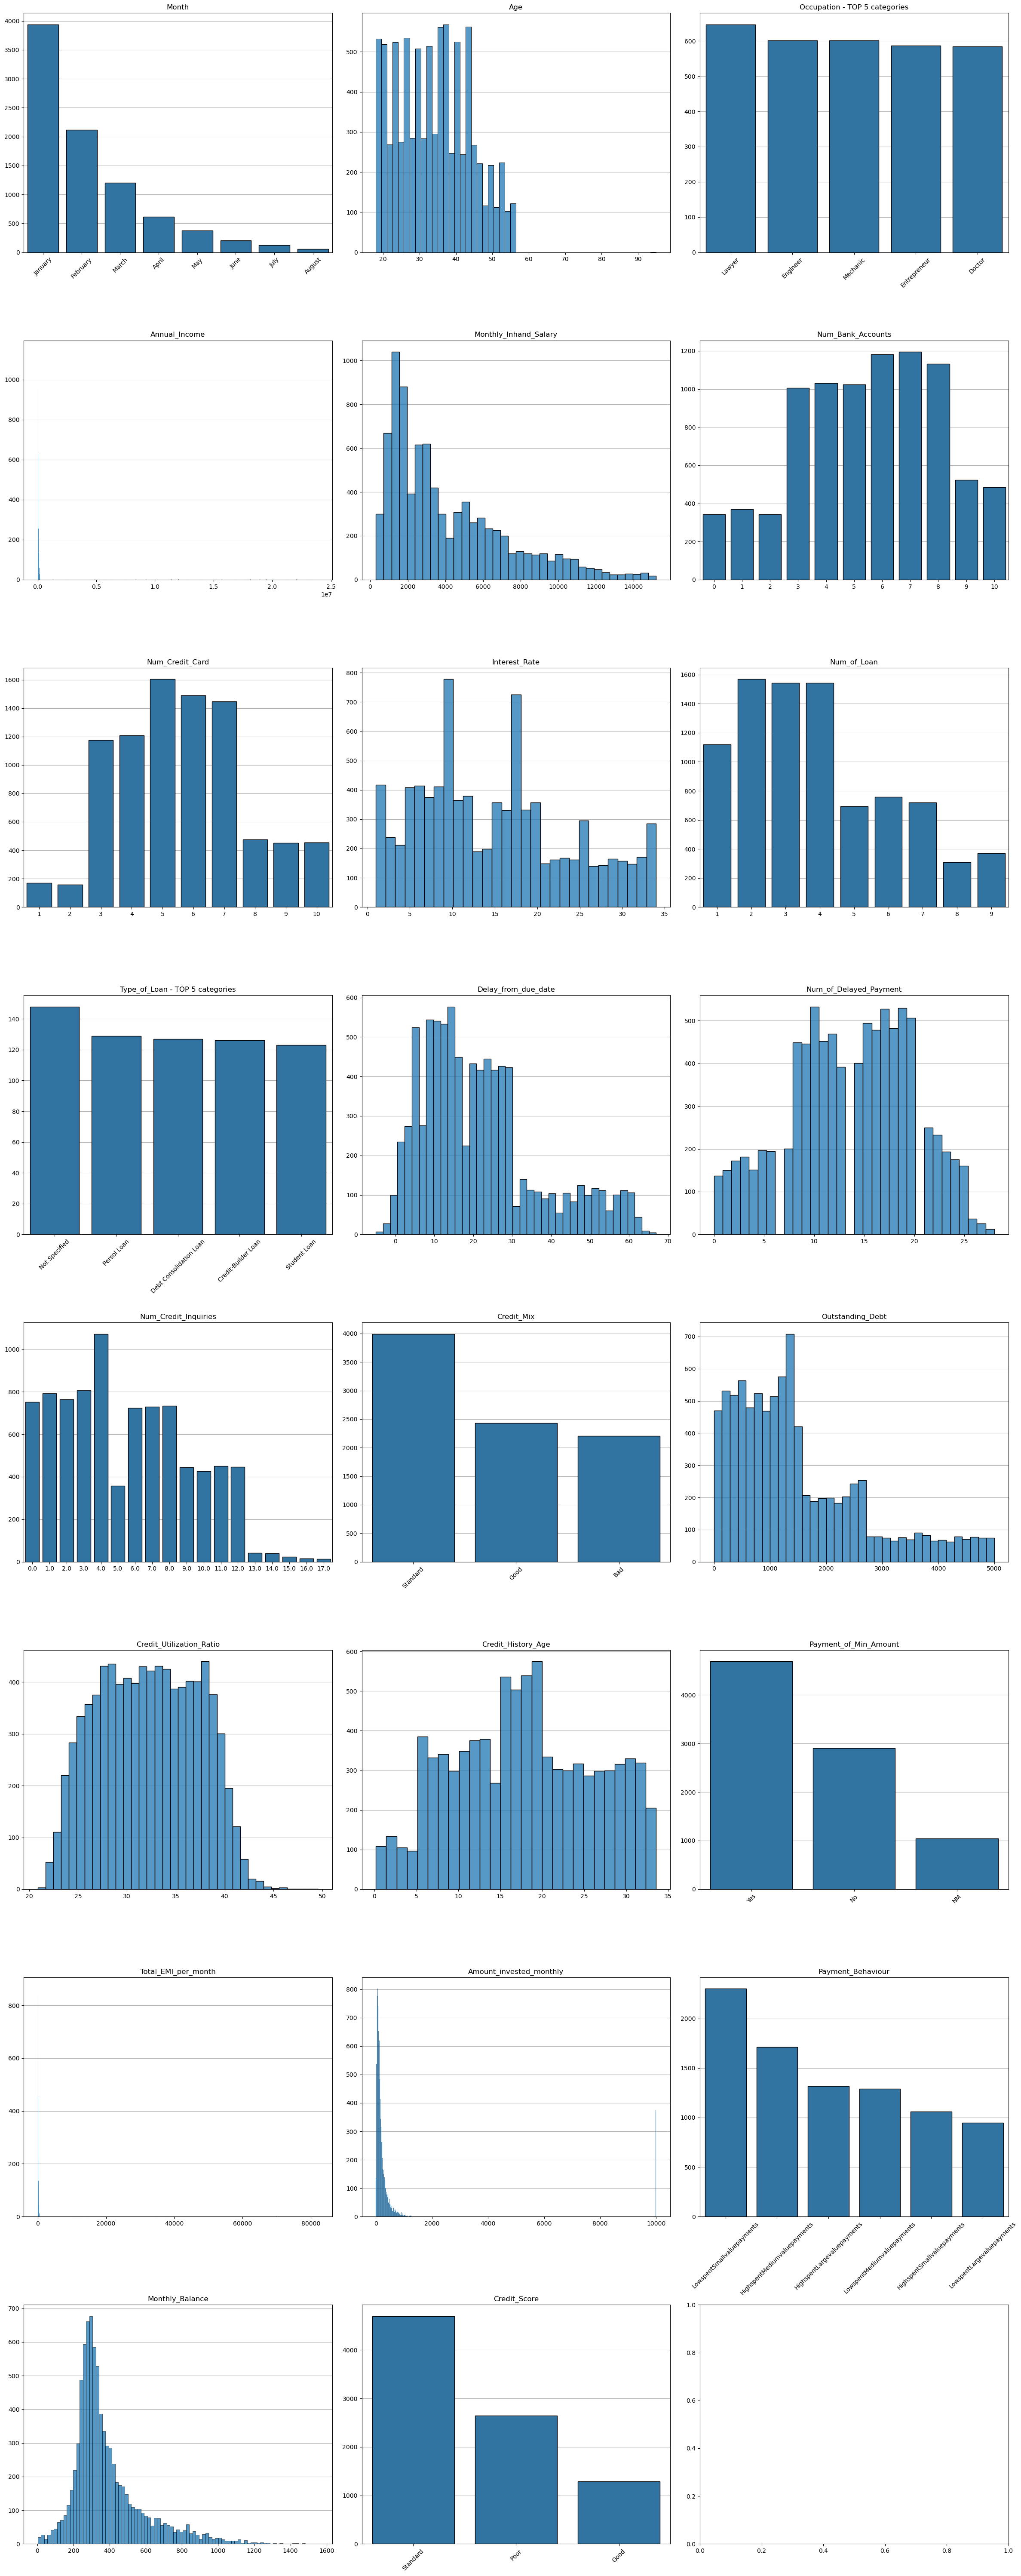

In [18]:
hf.draw_distribution(customer_data, subplot_size=(24, 60), subplot_cols=3, label_rot_for_categorical=45)

In [19]:
categorical_data = customer_data.select_dtypes(['object'])
categorical_data.describe()

,Month,Occupation,Type_of_Loan,Credit_Mix,Payment_of_Min_Amount,Payment_Behaviour,Credit_Score
count,8631,8631,8631,8631,8631,8631,8631
unique,8,15,4959,3,3,6,3
top,January,Lawyer,Not Specified,Standard,Yes,LowspentSmallvaluepayments,Standard
freq,3939,647,148,3992,4690,2301,4698


In [20]:
numerical_data = customer_data.select_dtypes(['int32', 'float32', 'int64', 'float64'])
numerical_data.head()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
0,23,19114.12,1824.84,3,4,3,4,3,8.00,4.00,809.98,22.54,22.58,49.57,178.34,244.57
1,28,34847.84,3037.99,2,4,6,1,7,1.00,2.00,605.03,38.55,26.67,18.82,40.39,484.59
2,34,143162.64,12187.22,1,5,8,3,13,6.00,3.00,1303.01,41.70,17.83,246.99,232.86,998.87
3,54,30689.89,2612.49,2,5,4,1,0,6.00,4.00,632.46,26.54,17.25,16.42,81.23,433.60
4,33,131313.40,11242.78,0,1,8,2,0,3.00,2.00,352.16,32.20,30.58,137.64,378.17,858.46


In [21]:
numerical_data, numerical_data_describe = hf.numeric_describe(customer_data)
numerical_data_describe

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00,8631.00
mean,34.01,188492.53,4113.41,5.49,5.60,14.99,3.93,21.65,13.60,5.40,1482.58,32.19,17.85,1320.06,610.63,386.39
std,9.92,1503637.03,3142.50,2.57,2.07,8.84,2.21,15.13,6.20,3.72,1180.27,5.04,8.35,8056.83,2008.86,198.14
min,18.00,7006.03,303.65,0.00,1.00,1.00,1.00,-5.00,0.00,0.00,0.23,20.88,0.17,4.46,0.00,2.63
25%,26.00,19137.65,1599.04,4.00,4.00,8.00,2.00,10.00,9.00,2.00,591.13,28.03,11.33,40.97,71.05,266.63
50%,34.00,36825.36,3043.15,6.00,6.00,14.00,4.00,19.00,14.00,5.00,1210.62,32.19,17.75,76.37,129.81,326.81
75%,42.00,71491.68,5868.91,7.00,7.00,20.00,6.00,29.00,18.00,8.00,2081.62,36.37,24.42,165.49,258.62,451.27
max,95.00,23912939.00,15204.63,10.00,10.00,34.00,9.00,67.00,28.00,17.00,4998.07,49.56,33.58,82122.00,10000.00,1552.95
unique,40.00,8625.00,8627.00,11.00,10.00,34.00,9.00,73.00,29.00,18.00,8505.00,8631.00,401.00,8630.00,8236.00,8631.00
var_coeff [%],29.17,797.72,76.40,46.89,37.01,58.95,56.31,69.87,45.55,68.85,79.61,15.66,46.79,610.34,328.98,51.28


Drawing boxplots [16/16]
[1, 253, 188, 0, 0, 0, 0, 275, 0, 0, 355, 1, 0, 504, 819, 645]


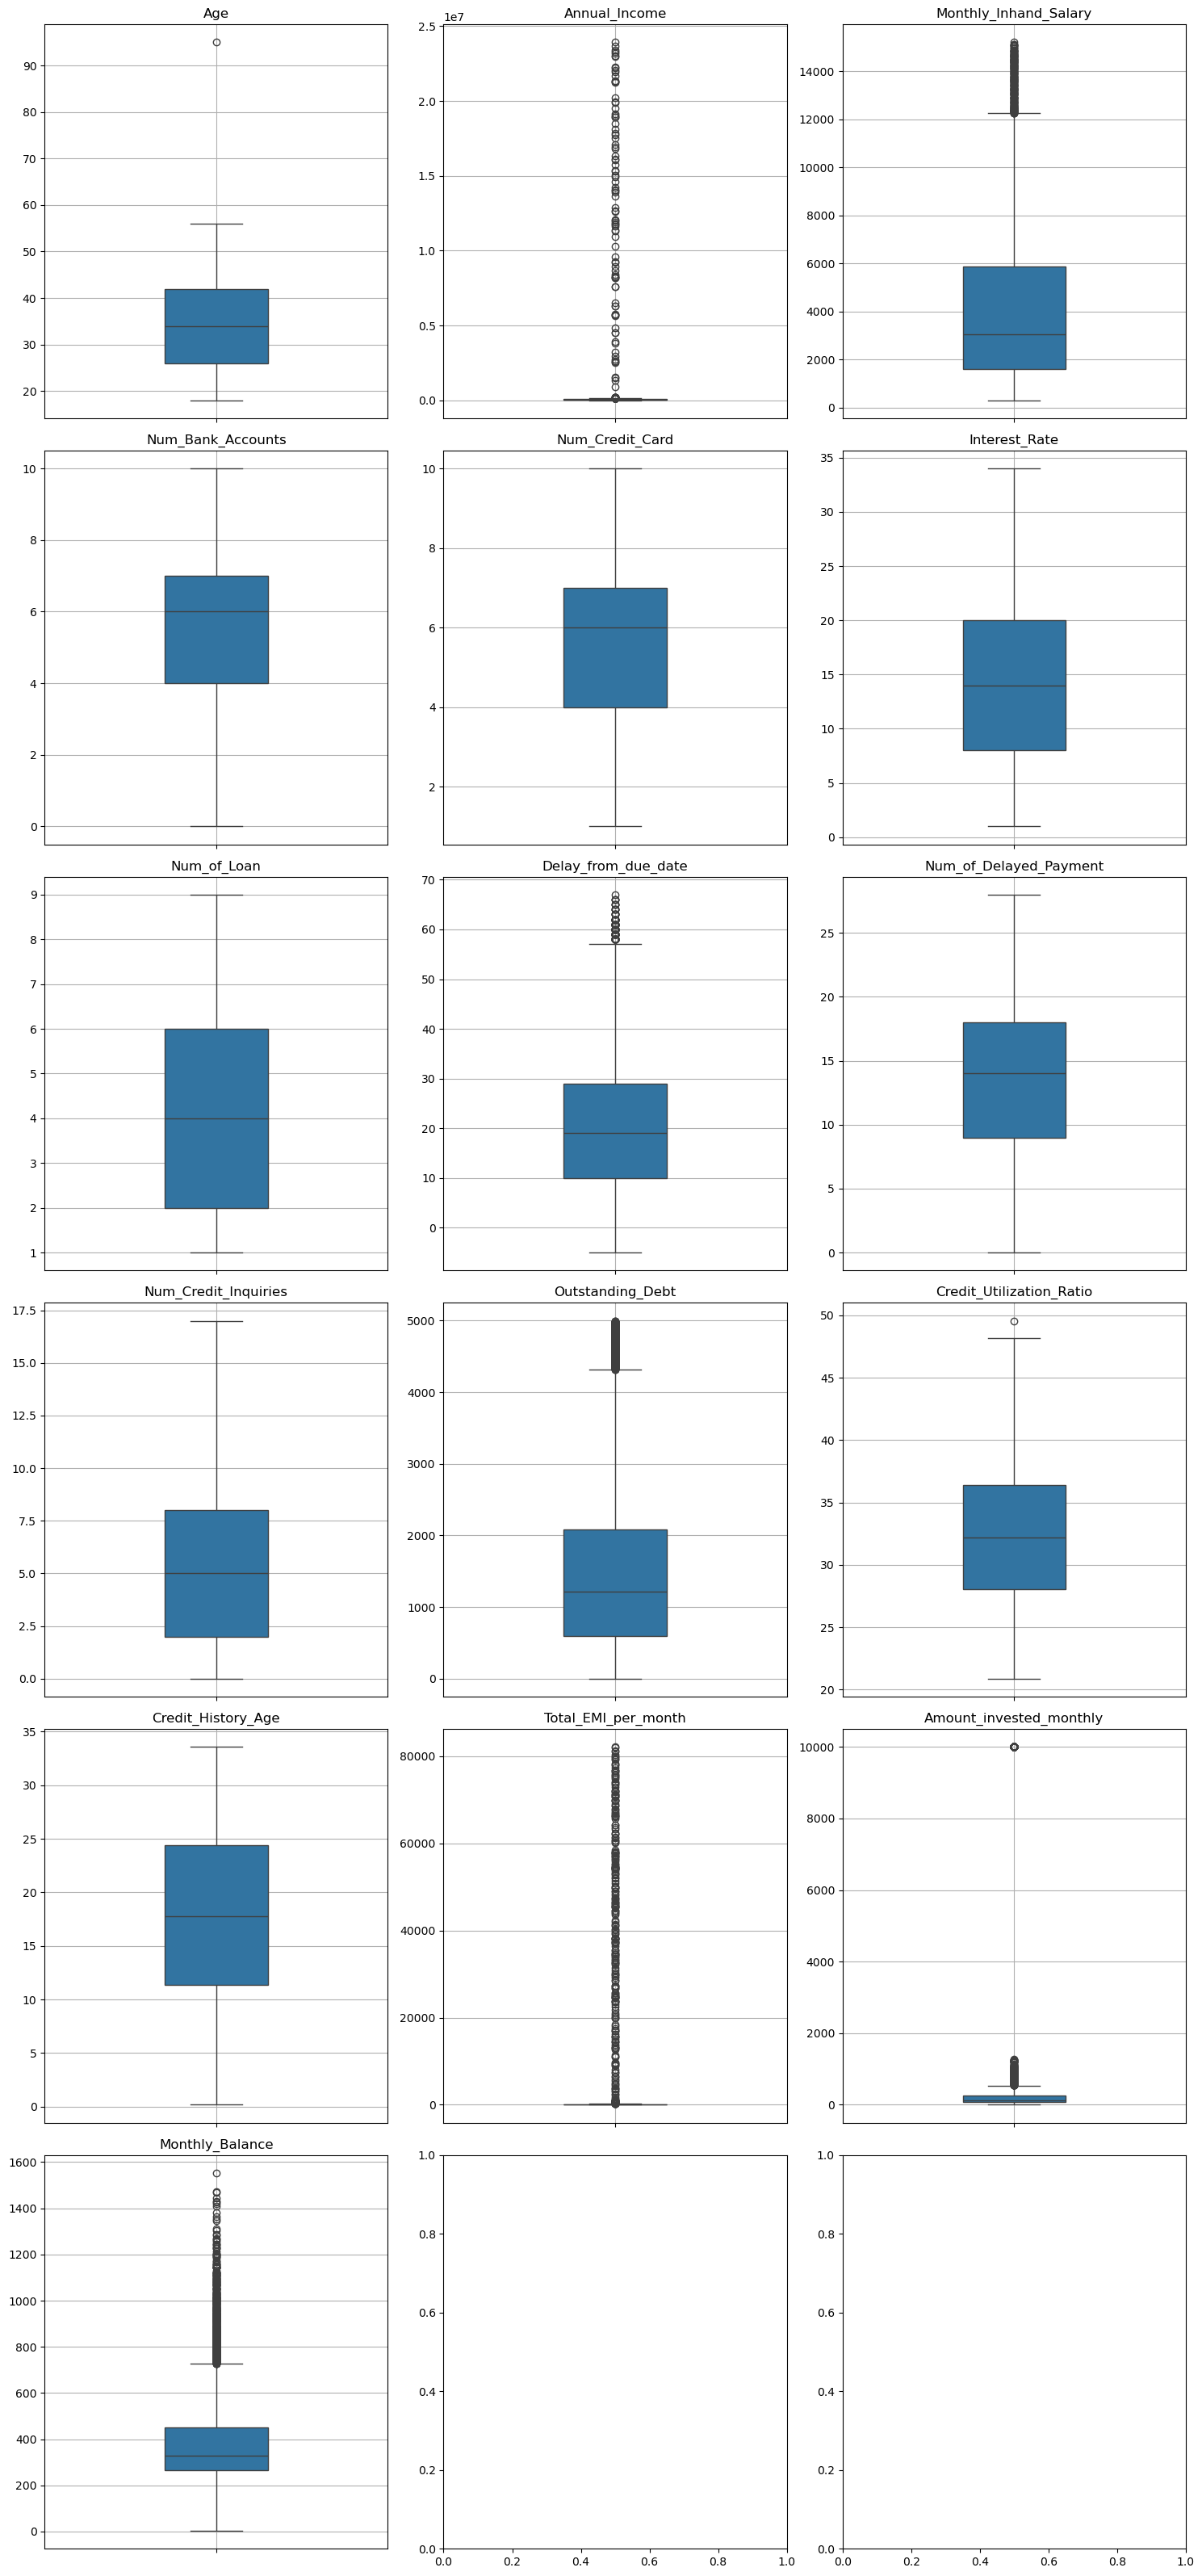

In [22]:
hf.draw_boxplots(numerical_data, subplot_size=(15, 32))

In [23]:
categorical_data.describe()

,Month,Occupation,Type_of_Loan,Credit_Mix,Payment_of_Min_Amount,Payment_Behaviour,Credit_Score
count,8631,8631,8631,8631,8631,8631,8631
unique,8,15,4959,3,3,6,3
top,January,Lawyer,Not Specified,Standard,Yes,LowspentSmallvaluepayments,Standard
freq,3939,647,148,3992,4690,2301,4698


In [24]:
customer_data = customer_data.drop(columns=['Month', 'Type_of_Loan', 'Credit_Mix'])
customer_data.select_dtypes('object').describe()

,Occupation,Payment_of_Min_Amount,Payment_Behaviour,Credit_Score
count,8631,8631,8631,8631
unique,15,3,6,3
top,Lawyer,Yes,LowspentSmallvaluepayments,Standard
freq,647,4690,2301,4698


In [25]:
customer_data.head(10)

,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,23,Scientist,19114.12,1824.84,3,4,3,4,3,8.00,4.00,809.98,22.54,22.58,No,49.57,178.34,LowspentSmallvaluepayments,244.57,Good
1,28,Teacher,34847.84,3037.99,2,4,6,1,7,1.00,2.00,605.03,38.55,26.67,No,18.82,40.39,HighspentLargevaluepayments,484.59,Good
2,34,Engineer,143162.64,12187.22,1,5,8,3,13,6.00,3.00,1303.01,41.70,17.83,No,246.99,232.86,HighspentSmallvaluepayments,998.87,Good
3,54,Entrepreneur,30689.89,2612.49,2,5,4,1,0,6.00,4.00,632.46,26.54,17.25,No,16.42,81.23,LowspentLargevaluepayments,433.60,Standard
4,33,Lawyer,131313.40,11242.78,0,1,8,2,0,3.00,2.00,352.16,32.20,30.58,NM,137.64,378.17,HighspentMediumvaluepayments,858.46,Good
5,44,Jourlist,31370.80,2825.23,1,6,12,2,2,0.00,2.00,421.43,28.22,26.50,No,46.62,298.74,LowspentSmallvaluepayments,227.16,Good
6,40,Teacher,33751.27,2948.61,5,5,20,3,16,20.00,4.00,1328.93,37.09,19.17,NM,65.01,117.31,HighspentMediumvaluepayments,362.55,Standard
7,32,Engineer,88640.24,7266.69,3,6,1,2,-1,0.00,3.00,950.36,28.21,25.42,No,135.17,98.93,HighspentLargevaluepayments,732.56,Standard
8,35,Entrepreneur,54392.16,4766.68,6,4,14,3,10,8.00,3.00,179.22,25.65,26.83,Yes,124.39,243.74,LowspentLargevaluepayments,378.54,Standard
9,39,Mager,8701.55,519.13,6,5,32,7,23,9.00,6.00,2602.69,39.90,9.00,Yes,36.55,34.72,LowspentLargevaluepayments,250.65,Poor


In [26]:
customer_data.shape

(8631, 20)

Categorical values encoding using OneHotEncoder, but for the target variable (Credit_Score) encode manually with 0, 1, 2 cause there are 3 unique
categories

In [27]:
credit_scores_encoded = customer_data['Credit_Score'].map({'Poor': 0, 'Standard': 1, 'Good': 2})
customer_data_encoded = hf.encode_categoric_data(customer_data.drop(columns='Credit_Score'))
customer_data_encoded['Credit_Score'] = credit_scores_encoded
customer_data_encoded.head()

1) Occupation - encoded 15 categories [reference category: 'Accountant']
2) Payment_of_Min_Amount - encoded 3 categories [reference category: 'NM']
3) Payment_Behaviour - encoded 6 categories [reference category: 'HighspentLargevaluepayments']


,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Occupation_Architect,Occupation_Developer,Occupation_Doctor,Occupation_Engineer,Occupation_Entrepreneur,Occupation_Jourlist,Occupation_Lawyer,Occupation_Mager,Occupation_Mechanic,Occupation_MediaMager,Occupation_Musician,Occupation_Scientist,Occupation_Teacher,Occupation_Writer,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_HighspentMediumvaluepayments,Payment_Behaviour_HighspentSmallvaluepayments,Payment_Behaviour_LowspentLargevaluepayments,Payment_Behaviour_LowspentMediumvaluepayments,Payment_Behaviour_LowspentSmallvaluepayments,Credit_Score
0,23,19114.12,1824.84,3,4,3,4,3,8.00,4.00,809.98,22.54,22.58,49.57,178.34,244.57,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,2
1,28,34847.84,3037.99,2,4,6,1,7,1.00,2.00,605.03,38.55,26.67,18.82,40.39,484.59,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,2
2,34,143162.64,12187.22,1,5,8,3,13,6.00,3.00,1303.01,41.70,17.83,246.99,232.86,998.87,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,2
3,54,30689.89,2612.49,2,5,4,1,0,6.00,4.00,632.46,26.54,17.25,16.42,81.23,433.60,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
4,33,131313.40,11242.78,0,1,8,2,0,3.00,2.00,352.16,32.20,30.58,137.64,378.17,858.46,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,2


### Correlation Matrix

<Axes: >

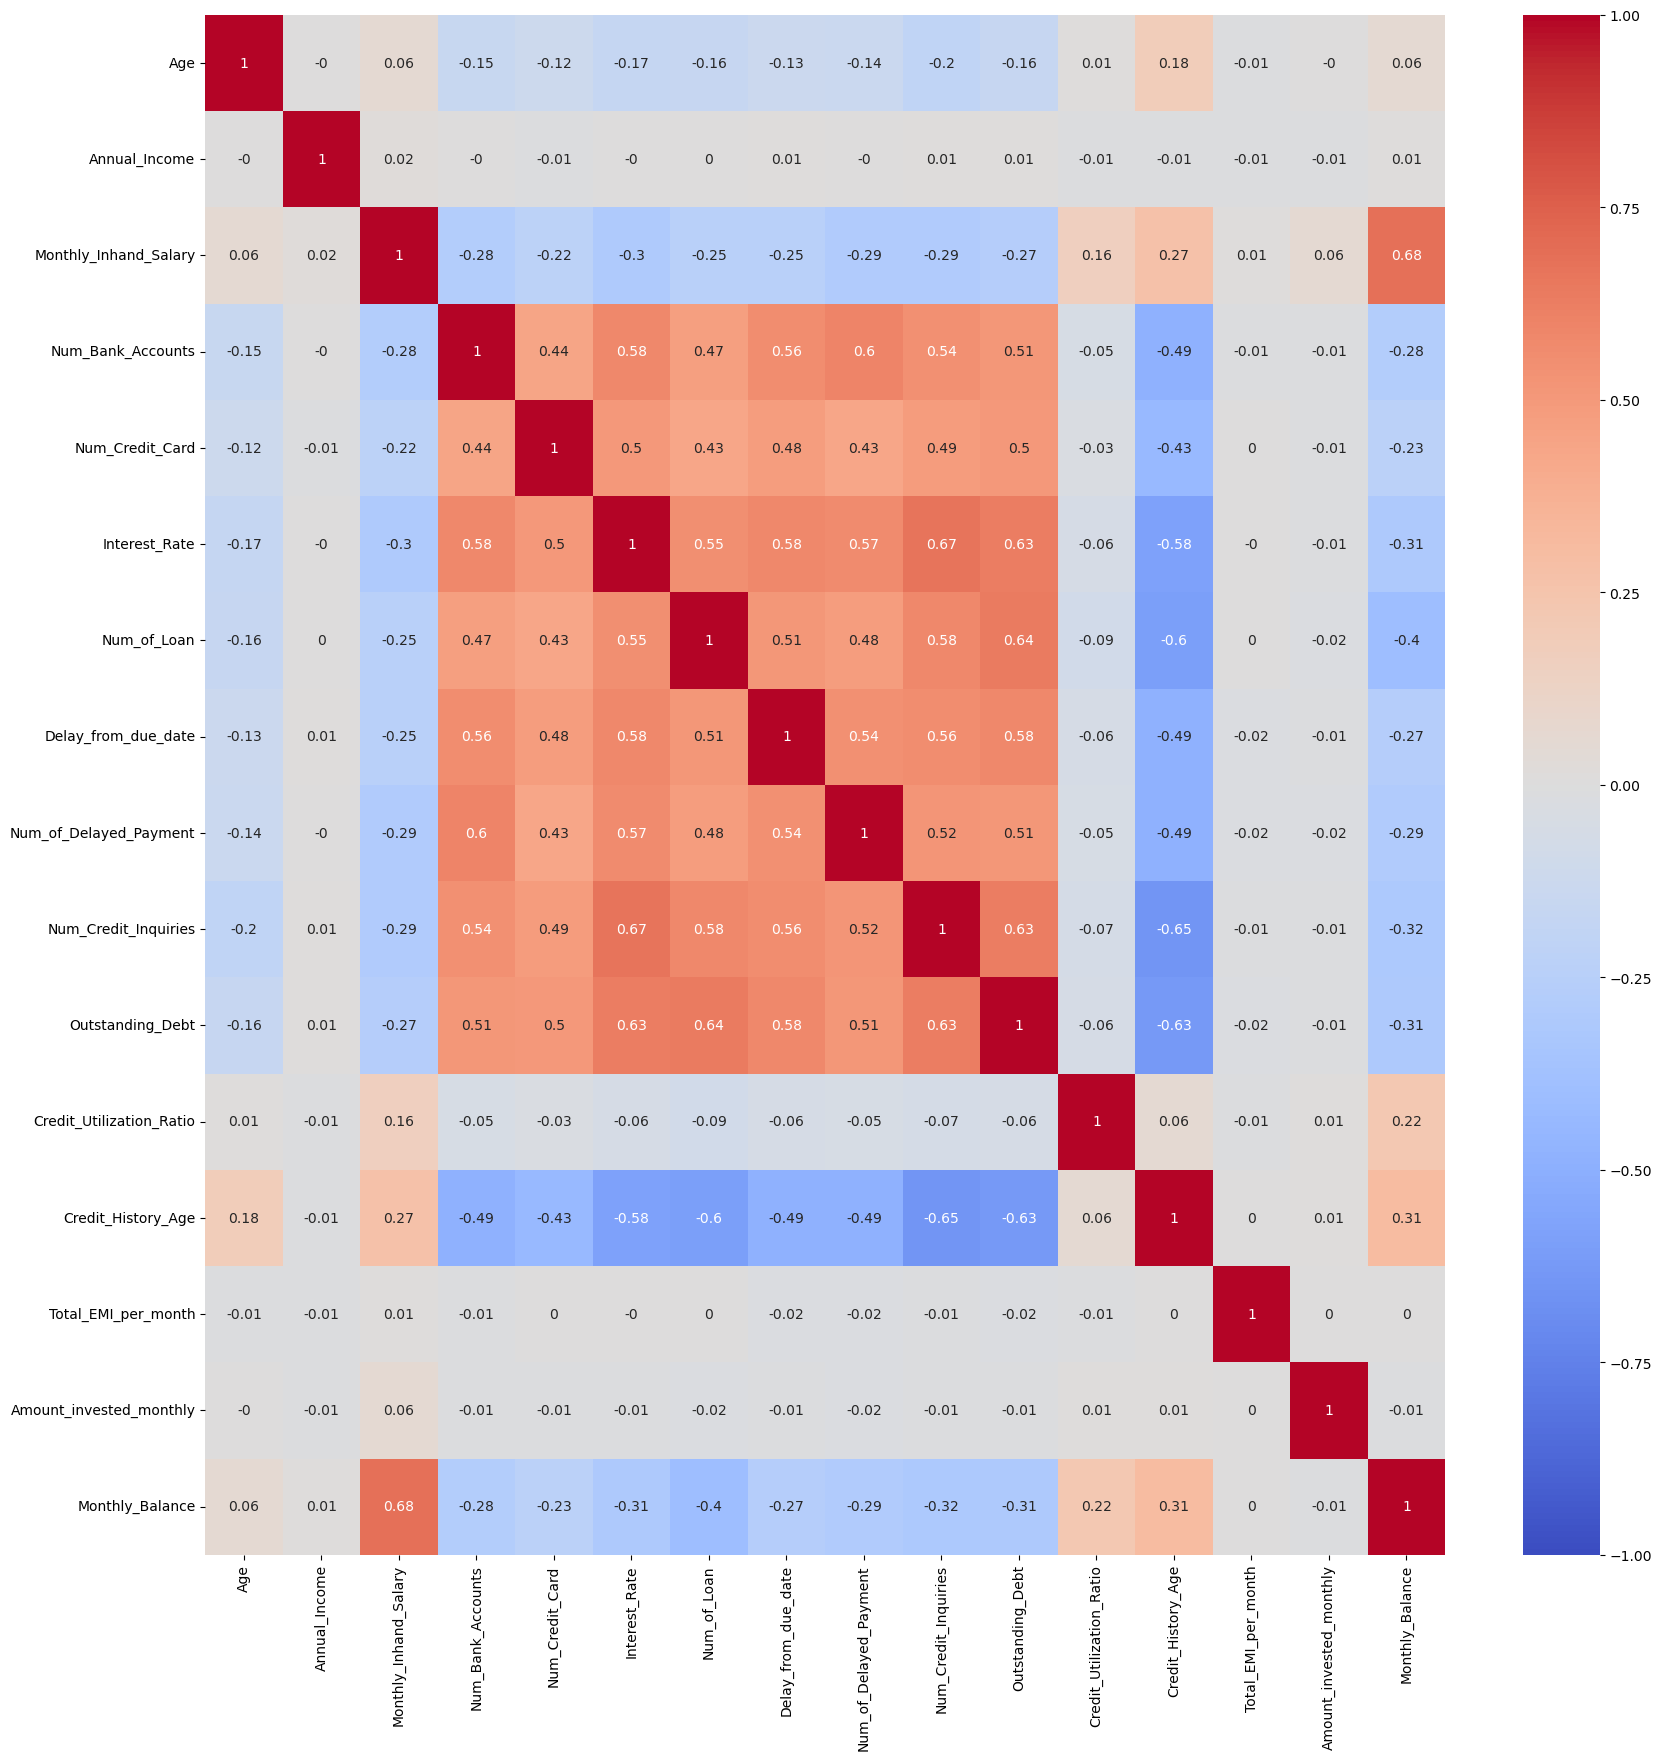

In [28]:
numeric_corr = numerical_data.corr().round(decimals=2)
plt.figure(figsize=(20, 20))
sns.heatmap(numeric_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

#### VIF (Variance Inflation Factor) analysis to determine linearity degree between independent variables, encoded categorical variables are included
$$ VIF_i = \frac{1}{1 - {R_i}^2} \;\;\;\;\;\;\; i = 1, 2 ... k $$

In [29]:
"""None of the variables has VIF > 10 so no need to drop any of them"""
print( hf.VIF( customer_data_encoded.drop(columns='Credit_Score') ) )

const                                            143.12
Age                                                1.06
Annual_Income                                      1.00
Monthly_Inhand_Salary                              2.10
Num_Bank_Accounts                                  2.03
Num_Credit_Card                                    1.55
Interest_Rate                                      2.51
Num_of_Loan                                        2.30
Delay_from_due_date                                2.00
Num_of_Delayed_Payment                             1.98
Num_Credit_Inquiries                               2.63
Outstanding_Debt                                   2.52
Credit_Utilization_Ratio                           1.05
Credit_History_Age                                 2.27
Total_EMI_per_month                                1.00
Amount_invested_monthly                            1.01
Monthly_Balance                                    3.00
Occupation_Architect                            

All of the numerical variables can be used for further analysis because of low VIF values

In [30]:
customer_data_encoded.head()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Occupation_Architect,Occupation_Developer,Occupation_Doctor,Occupation_Engineer,Occupation_Entrepreneur,Occupation_Jourlist,Occupation_Lawyer,Occupation_Mager,Occupation_Mechanic,Occupation_MediaMager,Occupation_Musician,Occupation_Scientist,Occupation_Teacher,Occupation_Writer,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_HighspentMediumvaluepayments,Payment_Behaviour_HighspentSmallvaluepayments,Payment_Behaviour_LowspentLargevaluepayments,Payment_Behaviour_LowspentMediumvaluepayments,Payment_Behaviour_LowspentSmallvaluepayments,Credit_Score
0,23,19114.12,1824.84,3,4,3,4,3,8.00,4.00,809.98,22.54,22.58,49.57,178.34,244.57,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,2
1,28,34847.84,3037.99,2,4,6,1,7,1.00,2.00,605.03,38.55,26.67,18.82,40.39,484.59,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,2
2,34,143162.64,12187.22,1,5,8,3,13,6.00,3.00,1303.01,41.70,17.83,246.99,232.86,998.87,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,2
3,54,30689.89,2612.49,2,5,4,1,0,6.00,4.00,632.46,26.54,17.25,16.42,81.23,433.60,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
4,33,131313.40,11242.78,0,1,8,2,0,3.00,2.00,352.16,32.20,30.58,137.64,378.17,858.46,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,2


In [31]:
customer_data_encoded['Credit_Score'].value_counts().sort_index()

Credit_Score
0    2645
1    4698
2    1288
Name: count, dtype: int64

### Scalling numerical data (MinMax scaling)

In [32]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()
cols_to_transform = customer_data_encoded.loc[:, :'Monthly_Balance'].columns

customer_data_scaled = customer_data_encoded.copy() 
customer_data_scaled[cols_to_transform] = minmax_scaler.fit_transform( customer_data_scaled[cols_to_transform] )
customer_data_scaled.head()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Occupation_Architect,Occupation_Developer,Occupation_Doctor,Occupation_Engineer,Occupation_Entrepreneur,Occupation_Jourlist,Occupation_Lawyer,Occupation_Mager,Occupation_Mechanic,Occupation_MediaMager,Occupation_Musician,Occupation_Scientist,Occupation_Teacher,Occupation_Writer,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_HighspentMediumvaluepayments,Payment_Behaviour_HighspentSmallvaluepayments,Payment_Behaviour_LowspentLargevaluepayments,Payment_Behaviour_LowspentMediumvaluepayments,Payment_Behaviour_LowspentSmallvaluepayments,Credit_Score
0,0.06,0.00,0.10,0.30,0.33,0.06,0.38,0.11,0.29,0.24,0.16,0.06,0.67,0.00,0.02,0.16,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,2
1,0.13,0.00,0.18,0.20,0.33,0.15,0.00,0.17,0.04,0.12,0.12,0.62,0.79,0.00,0.00,0.31,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,2
2,0.21,0.01,0.80,0.10,0.44,0.21,0.25,0.25,0.21,0.18,0.26,0.73,0.53,0.00,0.02,0.64,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,2
3,0.47,0.00,0.15,0.20,0.44,0.09,0.00,0.07,0.21,0.24,0.13,0.20,0.51,0.00,0.01,0.28,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
4,0.19,0.01,0.73,0.00,0.00,0.21,0.12,0.07,0.11,0.12,0.07,0.39,0.91,0.00,0.04,0.55,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,2


#### Using Lasso Logistic Regression for feature selection

In [33]:
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.model_selection import train_test_split

random_state = 68
X = customer_data_scaled.drop(columns='Credit_Score')
y = customer_data_scaled['Credit_Score']

"""Splitting data into training (70 %), validation (15 %), and test (15 %) sets"""
X_train, X_valid_test, y_train, y_valid_test = train_test_split(X, y, 
                                                                train_size=0.7, 
                                                                random_state=random_state, 
                                                                stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_valid_test, y_valid_test, 
                                                    train_size=0.5, 
                                                    random_state=random_state, 
                                                    stratify=y_valid_test)

logrCV_model = LogisticRegressionCV(
						multi_class='multinomial',
                        solver='saga',
    					penalty='l1',
                        class_weight='balanced',
                        max_iter=2000,
                        tol=1e-4, 
                        cv=5, 
                        random_state=random_state
        			)
logrCV_model.fit(
    X=X_train, 
    y=y_train
)

# print(logrCV_model.coef_.ravel())
col_names = X_train.columns
coeffs = logrCV_model.coef_.ravel()
selected_features_mask = coeffs != 0 
# selected feature names
selected_features = [c_name for c_name, sel_mask in zip(col_names, selected_features_mask) if sel_mask]
selected_features, len(selected_features)

e:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1946: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


(['Age',
  'Num_Bank_Accounts',
  'Num_Credit_Card',
  'Interest_Rate',
  'Delay_from_due_date',
  'Num_Credit_Inquiries',
  'Outstanding_Debt',
  'Credit_History_Age',
  'Total_EMI_per_month',
  'Amount_invested_monthly',
  'Occupation_Architect',
  'Occupation_Developer',
  'Occupation_Engineer',
  'Occupation_MediaMager',
  'Occupation_Musician',
  'Occupation_Writer',
  'Payment_of_Min_Amount_No',
  'Payment_Behaviour_LowspentLargevaluepayments',
  'Payment_Behaviour_LowspentMediumvaluepayments',
  'Payment_Behaviour_LowspentSmallvaluepayments'],
 20)

### Logistic Regression Model
$$ p=P(Y=1)= \frac{1}{1+\exp{(-(\beta_0+\beta_1 X_1+...+\beta_k X_k))}}

In [34]:
"""Selecting only features with non-zero coefficients from Logistic Regression with L1 regularization"""
"""Final X_train, X_valid, X_test"""
X_train = X_train[selected_features]
X_valid = X_valid[selected_features]
X_test = X_test[selected_features]

start_time = time.time()
log_reg_model = LogisticRegression(
						multi_class='multinomial', 
						penalty=None,
						solver='lbfgs', 
						class_weight='balanced',
						random_state=random_state
					)
end_time = time.time()
print(f"Logistic Regression training time: {(end_time - start_time):.2f} seconds")

log_reg_model.fit(
    X=X_train, 
	y=y_train
)

y_probs_LR_train = log_reg_model.predict_proba(X_train)
y_probs_LR_valid = log_reg_model.predict_proba(X_valid)
y_probs_LR_test = log_reg_model.predict_proba(X_test)
y_pred_LR_train = log_reg_model.predict(X_train)
y_pred_LR_valid = log_reg_model.predict(X_valid)
y_pred_LR_test = log_reg_model.predict(X_test)

Logistic Regression training time: 0.00 seconds


e:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


#### Confusion Matrices

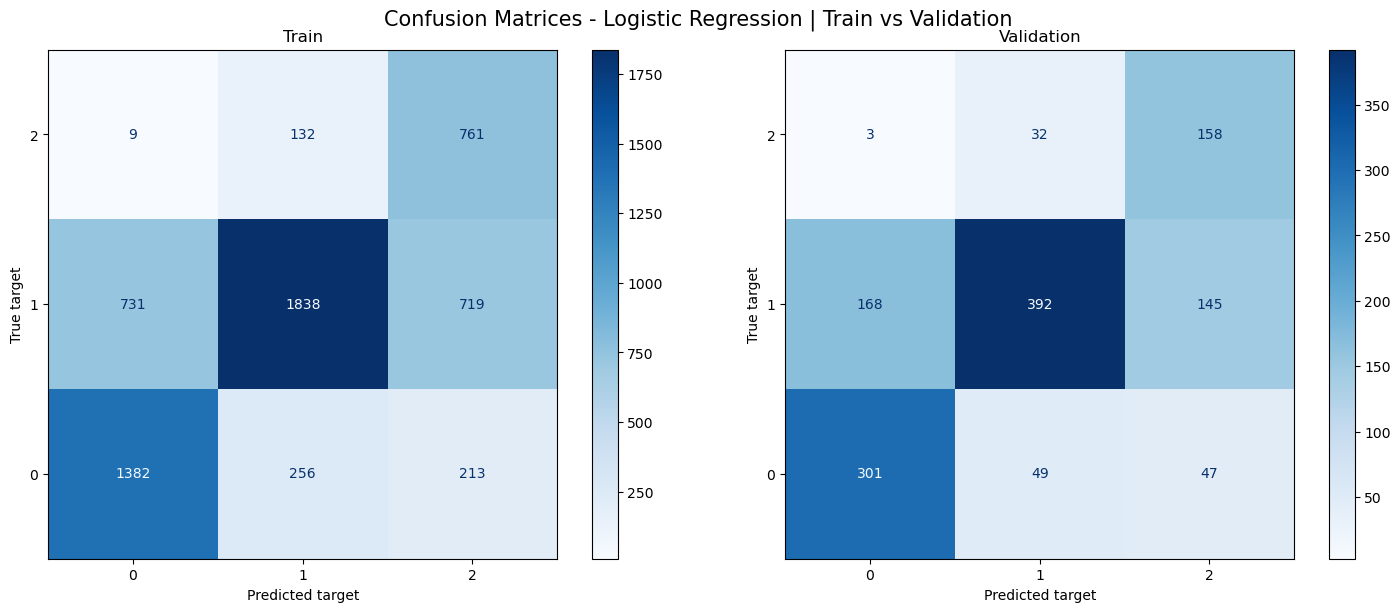

Train data:
Accuracy: 0.659
              precision    recall  f1-score   support

           0      0.651     0.747     0.696      1851
           1      0.826     0.559     0.667      3288
           2      0.449     0.844     0.587       902

    accuracy                          0.659      6041
   macro avg      0.642     0.716     0.650      6041
weighted avg      0.716     0.659     0.664      6041


Validation data:
Accuracy: 0.657
              precision    recall  f1-score   support

           0      0.638     0.758     0.693       397
           1      0.829     0.556     0.666       705
           2      0.451     0.819     0.582       193

    accuracy                          0.657      1295
   macro avg      0.639     0.711     0.647      1295
weighted avg      0.714     0.657     0.661      1295



In [35]:
cm_train_LR, cm_valid_LR = hf.display_confusion_matrix(y1_true=y_train, 
                                                       y1_pred=y_pred_LR_train, 
                                                       y2_true=y_valid,
                                                       y2_pred=y_pred_LR_valid, 
                                                       title='Confusion Matrices - Logistic Regression | Train vs Validation', 
                                                       cmap='Blues')
hf.display_quality_metrics(y_true=y_train, 
                           y_pred=y_pred_LR_train, 
                           y_probs=y_probs_LR_train, 
                           n_classes=3,
                           label='Train data', 
                           pr_curve_title='PR AUC Logistic Regression - Train data')
hf.display_quality_metrics(y_true=y_valid, 
                           y_pred=y_pred_LR_valid, 
                           y_probs=y_probs_LR_valid,
                           n_classes=3,
                           label='\nValidation data',
                           pr_curve_title='PR AUC Logistic Regression - Validation data')

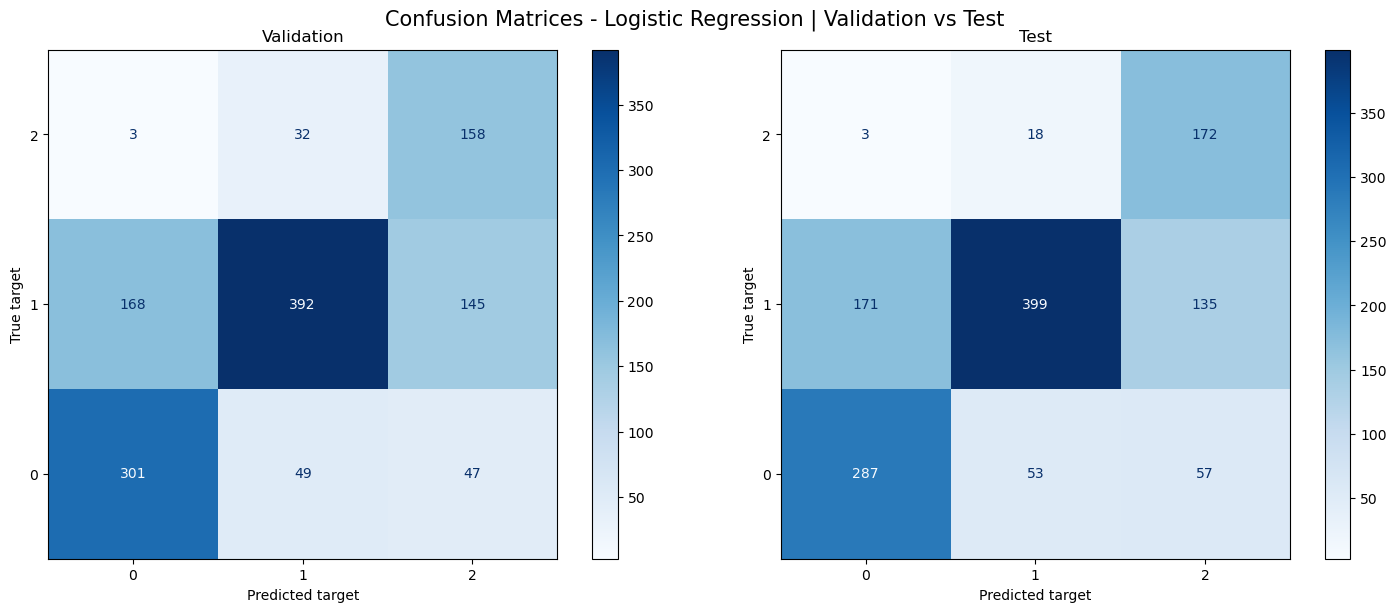

Validation data:
Accuracy: 0.657
              precision    recall  f1-score   support

           0      0.638     0.758     0.693       397
           1      0.829     0.556     0.666       705
           2      0.451     0.819     0.582       193

    accuracy                          0.657      1295
   macro avg      0.639     0.711     0.647      1295
weighted avg      0.714     0.657     0.661      1295


Test data:
Accuracy: 0.663
              precision    recall  f1-score   support

           0      0.623     0.723     0.669       397
           1      0.849     0.566     0.679       705
           2      0.473     0.891     0.618       193

    accuracy                          0.663      1295
   macro avg      0.648     0.727     0.655      1295
weighted avg      0.723     0.663     0.667      1295



In [36]:
cm_valid_LR, cm_test_LR = hf.display_confusion_matrix(y1_true=y_valid, 
                                                      y1_pred=y_pred_LR_valid, 
                                                      y2_true=y_test,
                                                      y2_pred=y_pred_LR_test, 
                                                      title='Confusion Matrices - Logistic Regression | Validation vs Test', 
                                                      cmap='Blues',
                                                      compare=['Validation', 'Test'])
hf.display_quality_metrics(y_true=y_valid, 
                           y_pred=y_pred_LR_valid, 
                           y_probs=y_probs_LR_valid, 
                           n_classes=3,
                           label='Validation data', 
                           pr_curve_title='PR AUC Logistic Regression - Validation data')
hf.display_quality_metrics(y_true=y_test, 
                           y_pred=y_pred_LR_test, 
                           y_probs=y_probs_LR_test,
                           n_classes=3,
                           label='\nTest data',
                           pr_curve_title='PR AUC Logistic Regression - Test data')

Calculating feature importances for Logistic regression model ...


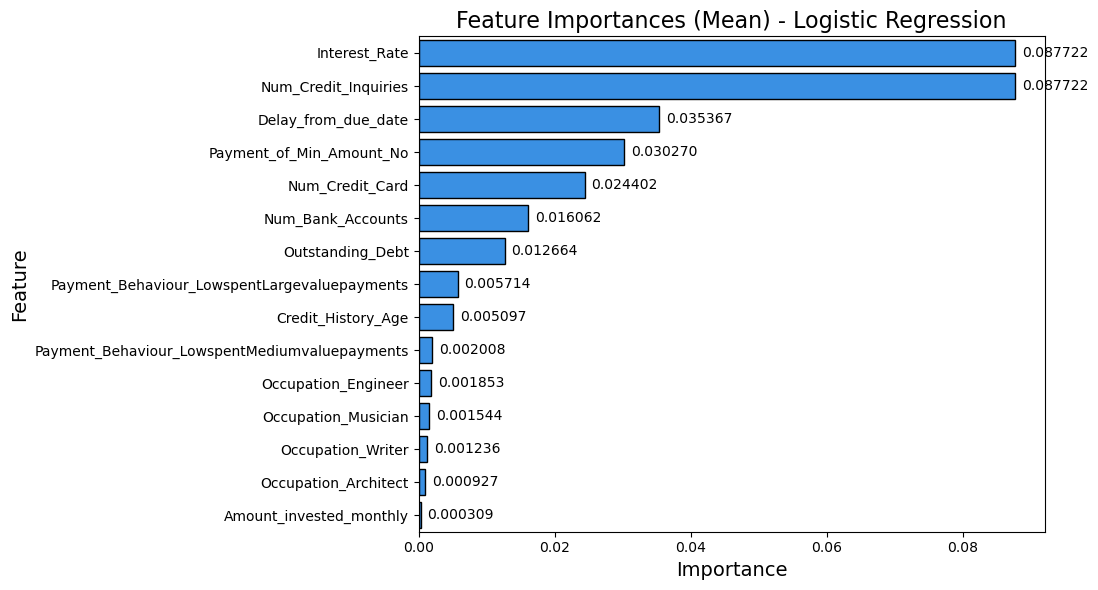

In [37]:
"""Feature importance for Logistic Regression model"""
lr_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(model=log_reg_model,
																	  model_name='Logistic Regression',
																	  X_data=X_valid,
																	  y_data=y_valid,
																	  n_reps=5,
																	  max_num_features=15,
																	  n_jobs=1)

#### PCA Visualization - Logistic Regression

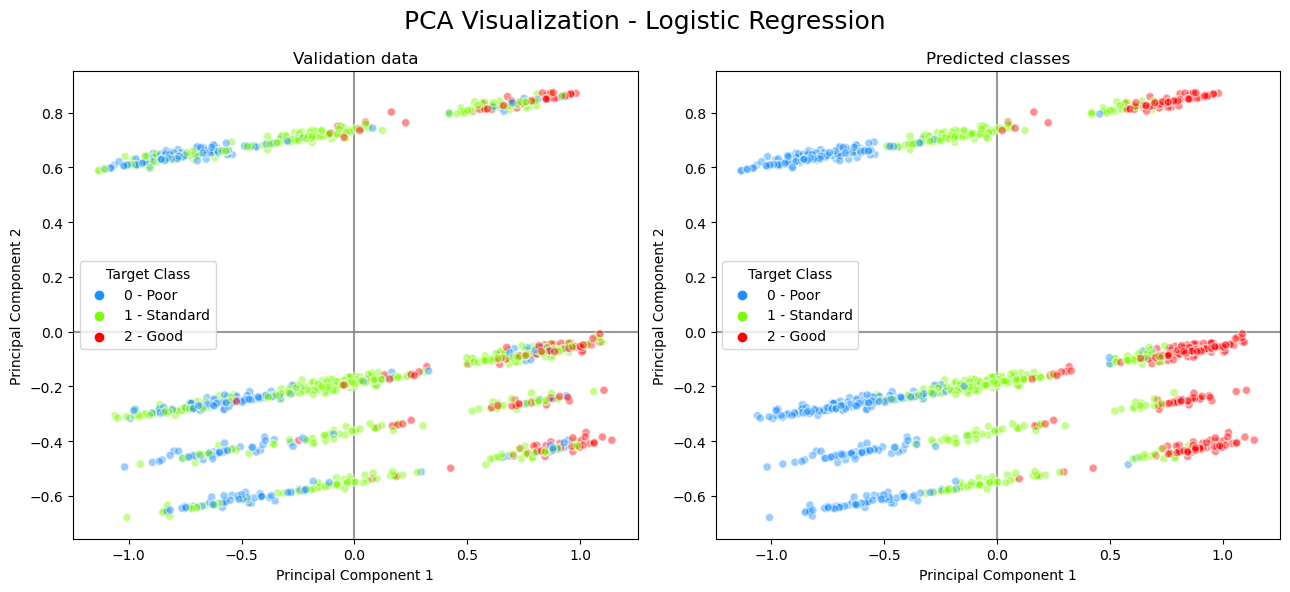

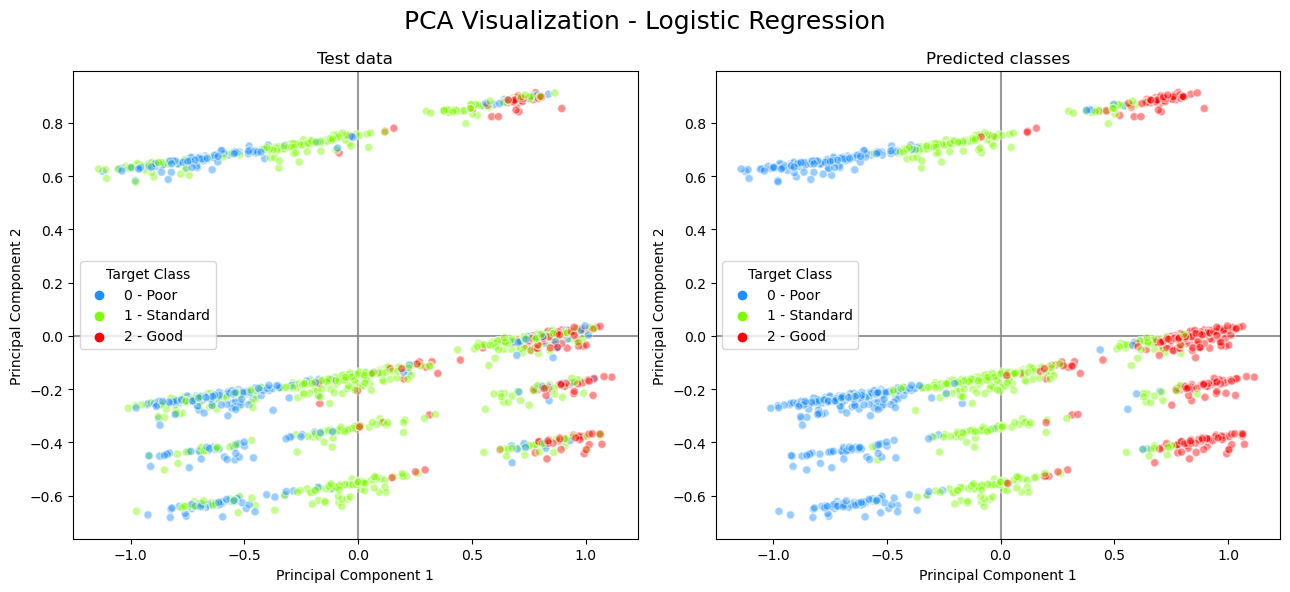

In [38]:
colors_dict = {0: 'dodgerblue', 1: 'lawngreen', 2: 'red'}
class_names_dict = {0: 'Poor', 1: 'Standard', 2: 'Good'}
hf.pca_visualization(X_true=X_valid, 
                     y_true=y_valid, 
                     y_pred=y_pred_LR_valid, 
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Logistic Regression',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_test, 
                     y_true=y_test, 
                     y_pred=y_pred_LR_test, 
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Logistic Regression',
                     valid_or_test='Test',
                     alpha=0.45)

Logistic Regression training time: 0.07 seconds


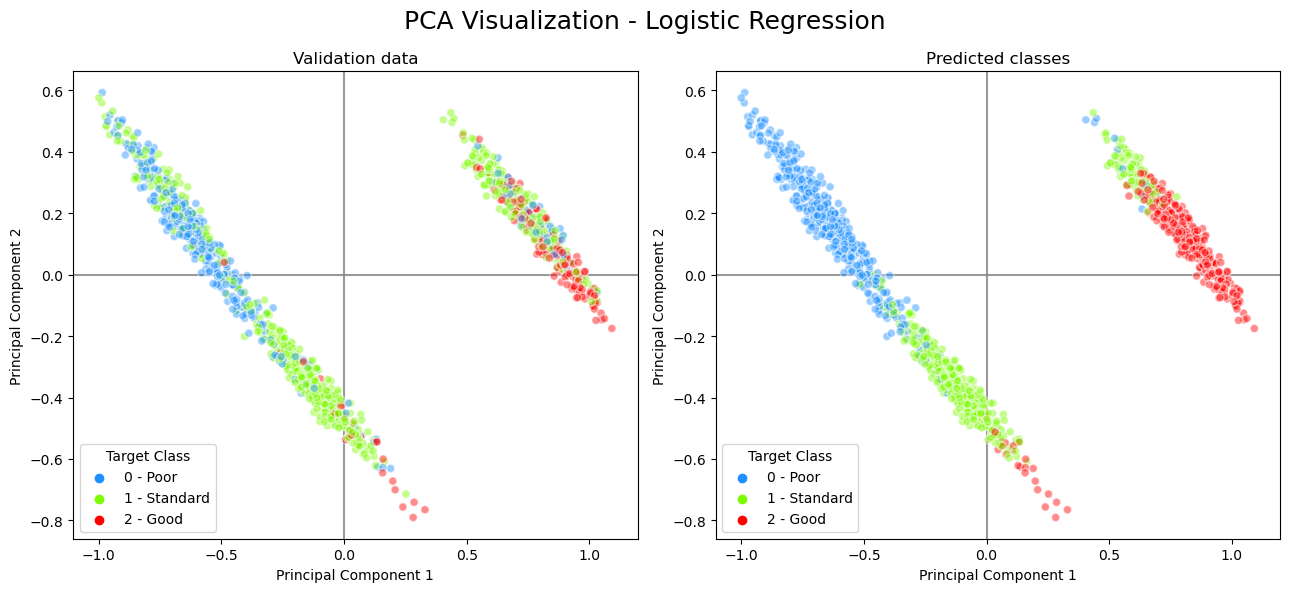

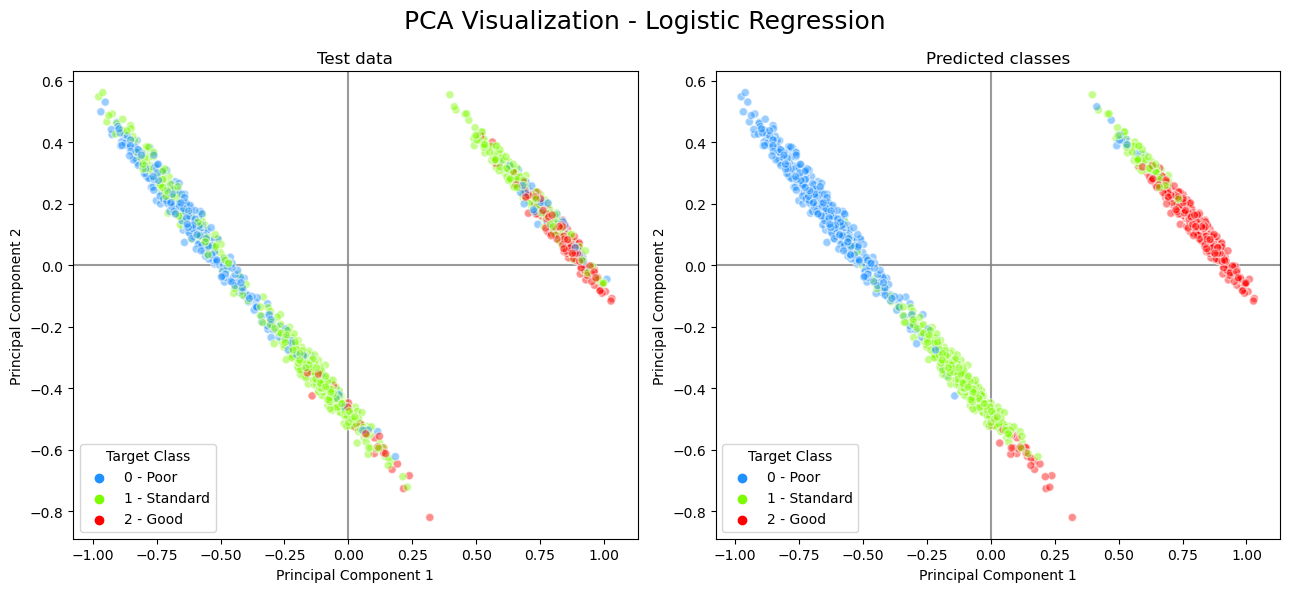

In [39]:
"""PCA for most important features based on feature importance plot"""
lr_most_important_feats = lr_feat_names_sorted_desc_by_importance[:7]
X_LR_train_important_feats = X_train[ lr_most_important_feats ]
X_LR_valid_important_feats = X_valid[ lr_most_important_feats ]
X_LR_test_important_feats = X_test[ lr_most_important_feats ]

"""Building Logistic Regression model using only most important features only for PCA visualization purposes"""
start_time = time.time()
lr_model_important_feats = LogisticRegression(class_weight=log_reg_model.class_weight)
lr_model_important_feats.fit(
    X=X_LR_train_important_feats, 
    y=y_train
)
end_time = time.time()
print(f"Logistic Regression training time: {(end_time - start_time):.2f} seconds")

y_pred_LR_valid_imp_feats = lr_model_important_feats.predict( X_LR_valid_important_feats )
y_pred_LR_test_imp_feats = lr_model_important_feats.predict( X_LR_test_important_feats )

hf.pca_visualization(X_true=X_LR_valid_important_feats, 
                     y_true=y_valid, 
                     y_pred=y_pred_LR_valid_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Logistic Regression',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_LR_test_important_feats, 
                     y_true=y_test, 
                     y_pred=y_pred_LR_test_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Logistic Regression',
                     valid_or_test='Test',
                     alpha=0.45)

In [40]:
import torch

"""setting device"""
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

### XGBoost algorithm

In [ ]:
import xgboost as xgb

val_counts = y_train.value_counts()
class_freq_ratio = val_counts.loc[0] / val_counts.loc[1]

start_time = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    scale_pos_weight=class_freq_ratio,
    early_stopping_rounds=50,
	random_state=random_state
)

xgb_model.fit(
    X=X_train, 
    y=y_train, 
    eval_set=[(X_valid, y_valid)], 
    verbose=10
)
end_time = time.time()
print(f"XGBoost training time: {(end_time - start_time):.2f} seconds")

y_probs_XGB_train = xgb_model.predict_proba(X_train)
y_probs_XGB_valid = xgb_model.predict_proba(X_valid)
y_probs_XGB_test = xgb_model.predict_proba(X_test)
y_pred_XGB_train = xgb_model.predict(X_train)
y_pred_XGB_valid = xgb_model.predict(X_valid)
y_pred_XGB_test = xgb_model.predict(X_test)

[0]	validation_0-mlogloss:0.91504
[10]	validation_0-mlogloss:0.59396
[20]	validation_0-mlogloss:0.58429
[30]	validation_0-mlogloss:0.59161
[40]	validation_0-mlogloss:0.60022
[50]	validation_0-mlogloss:0.61188
[60]	validation_0-mlogloss:0.62039
[67]	validation_0-mlogloss:0.62867
XGBoost training time: 0.24 seconds


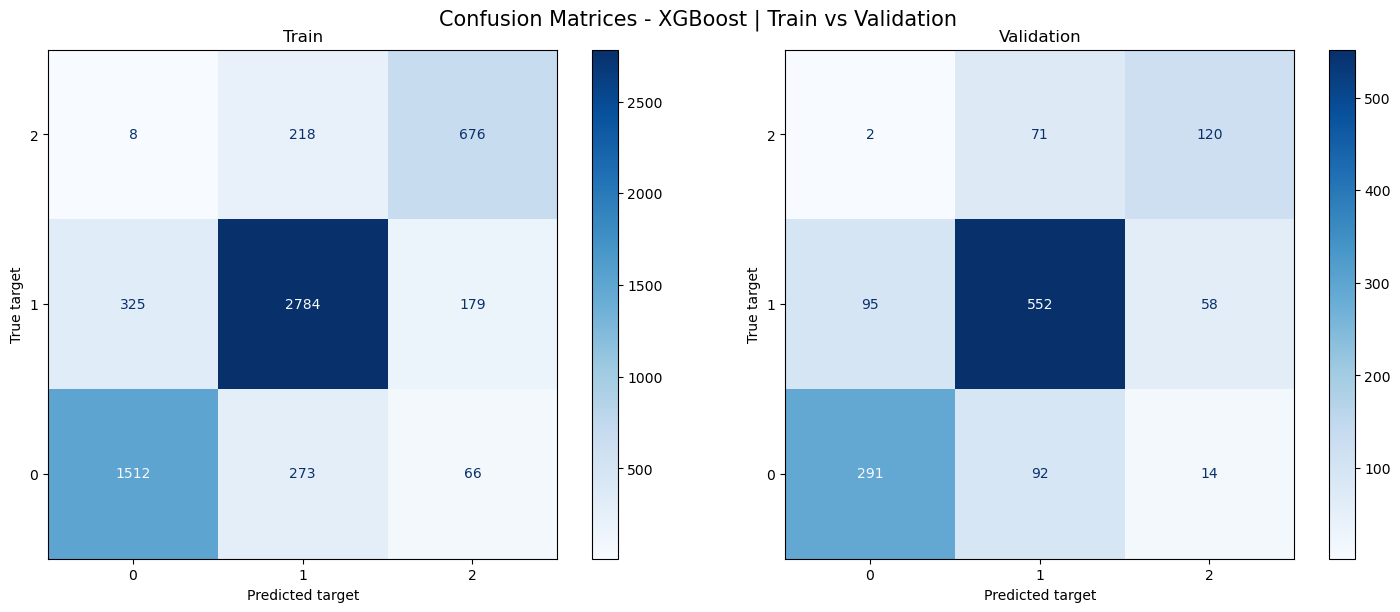

Train data:
Accuracy: 0.823
              precision    recall  f1-score   support

           0      0.820     0.817     0.818      1851
           1      0.850     0.847     0.848      3288
           2      0.734     0.749     0.742       902

    accuracy                          0.823      6041
   macro avg      0.801     0.804     0.803      6041
weighted avg      0.823     0.823     0.823      6041


Validation data:
Accuracy: 0.744
              precision    recall  f1-score   support

           0      0.750     0.733     0.741       397
           1      0.772     0.783     0.777       705
           2      0.625     0.622     0.623       193

    accuracy                          0.744      1295
   macro avg      0.716     0.713     0.714      1295
weighted avg      0.743     0.744     0.743      1295



In [42]:
cm_train_XGB, cm_valid_XGB = hf.display_confusion_matrix(y1_true=y_train, 
                                                         y1_pred=y_pred_XGB_train,
                                                         y2_true=y_valid, 
                                                         y2_pred=y_pred_XGB_valid,
                                                         title='Confusion Matrices - XGBoost | Train vs Validation', 
                                                         cmap="Blues")
hf.display_quality_metrics(y_true=y_train,
                           y_pred=y_pred_XGB_train,
                           y_probs=y_probs_XGB_train,
                           n_classes=3,
                           label='Train data',
                           pr_curve_title='PR AUC XGBoost - Train data')
hf.display_quality_metrics(y_true=y_valid,
                           y_pred=y_pred_XGB_valid,
                           y_probs=y_probs_XGB_valid,
                           n_classes=3,
                           label='\nValidation data',            
                           pr_curve_title='PR AUC XGBoost - Validation data')

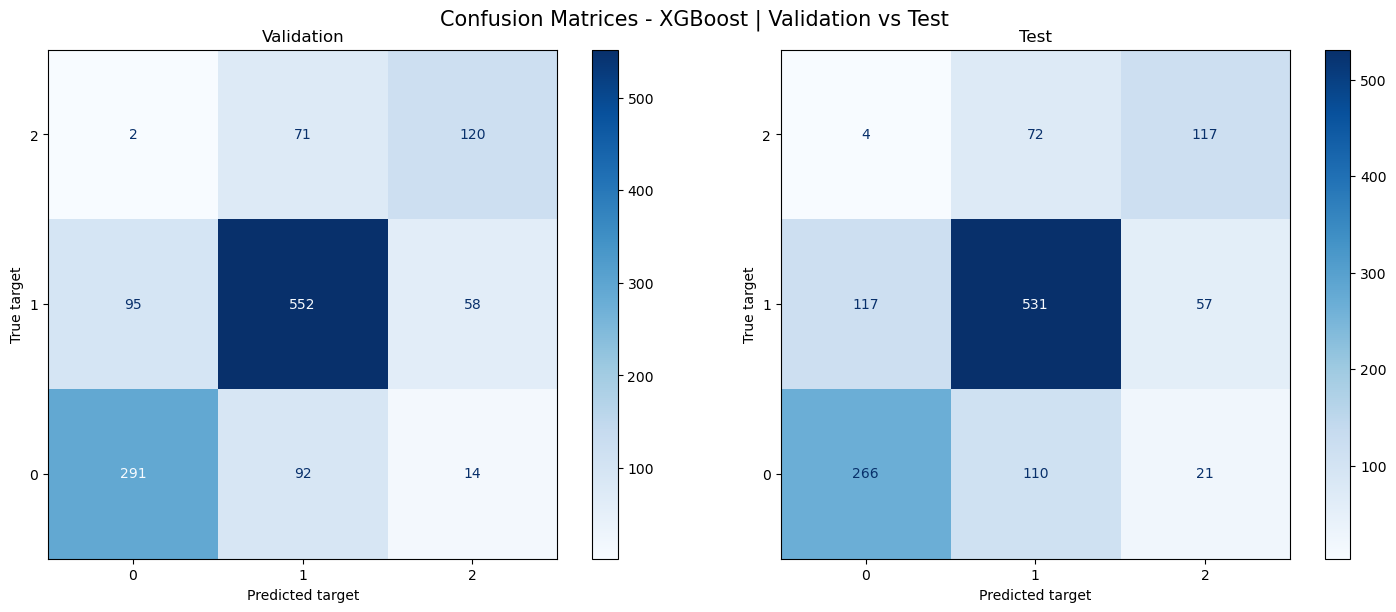

Validation data:
Accuracy: 0.744
              precision    recall  f1-score   support

           0      0.750     0.733     0.741       397
           1      0.772     0.783     0.777       705
           2      0.625     0.622     0.623       193

    accuracy                          0.744      1295
   macro avg      0.716     0.713     0.714      1295
weighted avg      0.743     0.744     0.743      1295


Test data:
Accuracy: 0.706
              precision    recall  f1-score   support

           0      0.687     0.670     0.679       397
           1      0.745     0.753     0.749       705
           2      0.600     0.606     0.603       193

    accuracy                          0.706      1295
   macro avg      0.677     0.676     0.677      1295
weighted avg      0.706     0.706     0.706      1295



In [43]:
cm_valid_XGB, cm_test_XGB = hf.display_confusion_matrix(y1_true=y_valid, 
                                                        y1_pred=y_pred_XGB_valid,
                                                        y2_true=y_test, 
                                                        y2_pred=y_pred_XGB_test,
                                                        title='Confusion Matrices - XGBoost | Validation vs Test', 
                                                        cmap="Blues",
                                                        compare=['Validation', 'Test'])
hf.display_quality_metrics(y_true=y_valid,
                           y_pred=y_pred_XGB_valid,
                           y_probs=y_probs_XGB_valid,
                           n_classes=3,
                           label='Validation data',
                           pr_curve_title='PR AUC XGBoost - Validation data')
hf.display_quality_metrics(y_true=y_test,
                           y_pred=y_pred_XGB_test,
                           y_probs=y_probs_XGB_test,
                           n_classes=3,
                           label='\nTest data',            
                           pr_curve_title='PR AUC XGBoost - Test data')

#### Visualizing decision trees and feature importance for XGBoost model

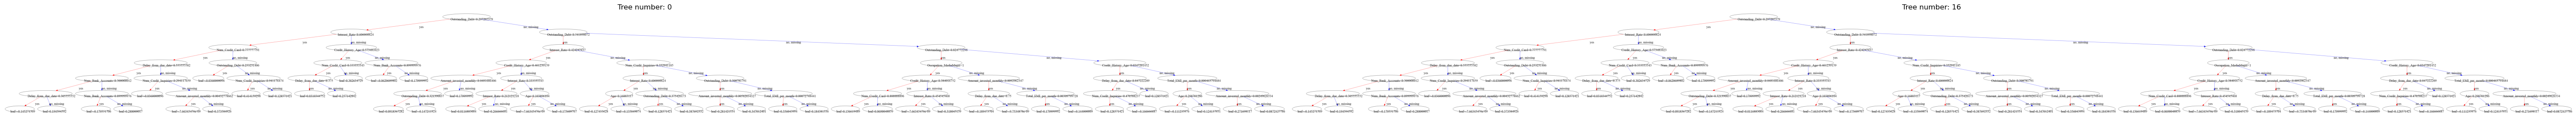

Calculating feature importances for Xgboost model ...


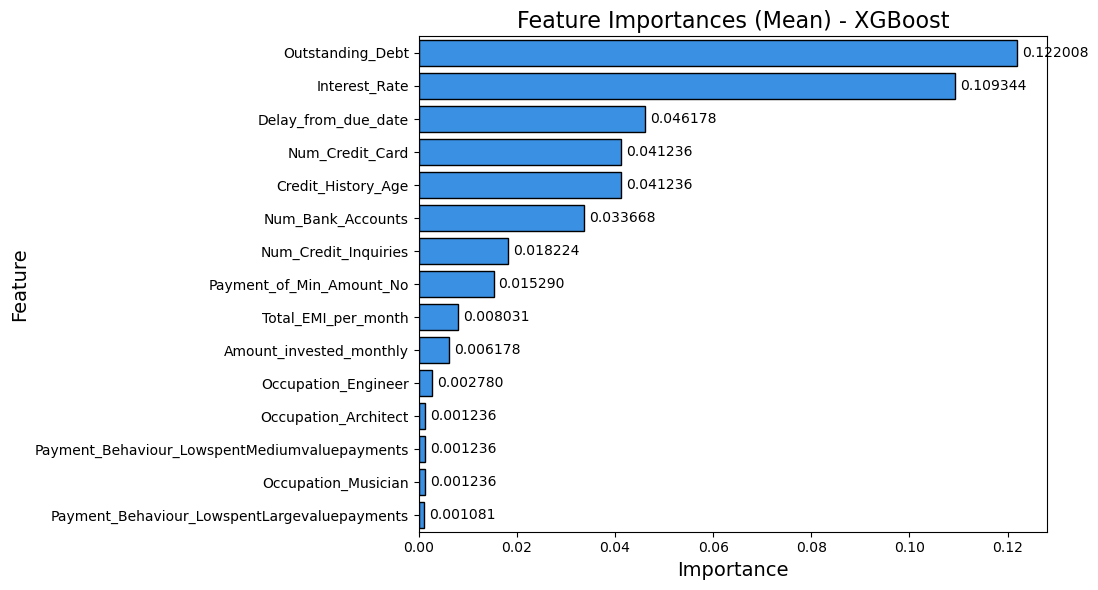

In [44]:
"""Plots decision trees for XGBoost model for chosen tree indices"""
tree_indices = [0, xgb_model.best_iteration-1]
fig, axes = plt.subplots(1, len(tree_indices), figsize=(60, 100)); axes = axes.flatten()
for tree_i, ax in zip(tree_indices, axes):
    xgb.plot_tree(xgb_model, tree_idx=tree_i, ax=ax)
    ax.set_title(f'Tree number: {tree_i}')
plt.tight_layout()
plt.show()

"""Plot feature importances for XGBoost model"""    
xgb_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(model=xgb_model,
                            										 model_name='XGBoost',
                            										 X_data=X_valid,
                            										 y_data=y_valid,
																	 n_reps=5,
																	 max_num_features=15,
																	 n_jobs=1)

#### PCA Visualization - XGBoost 

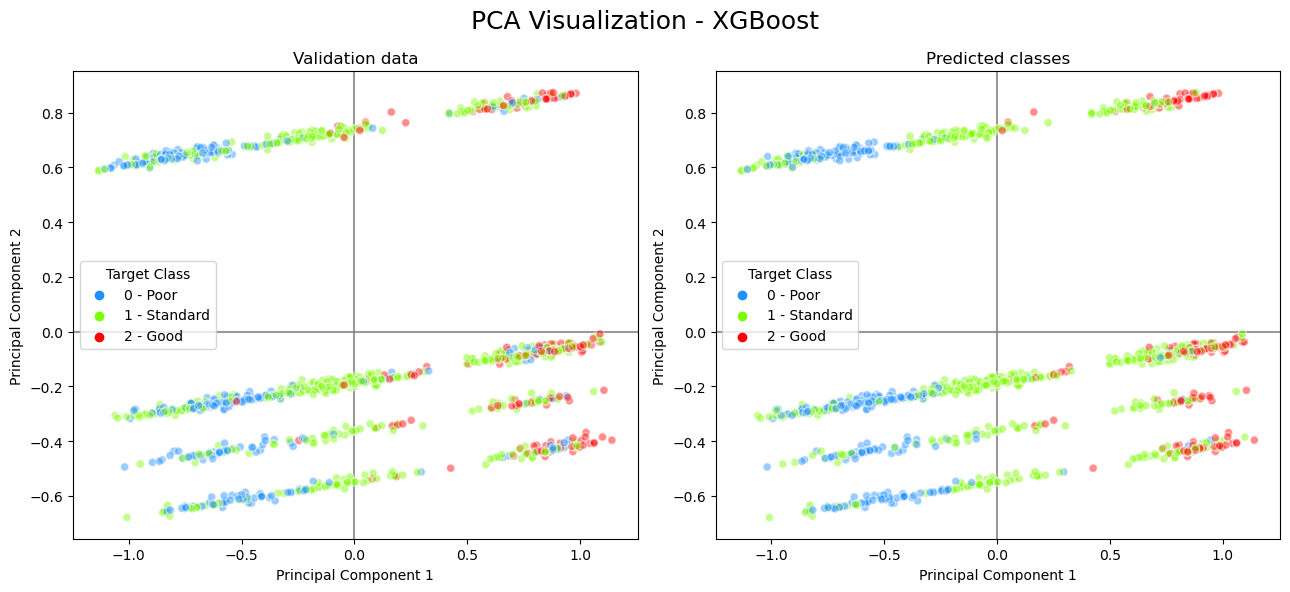

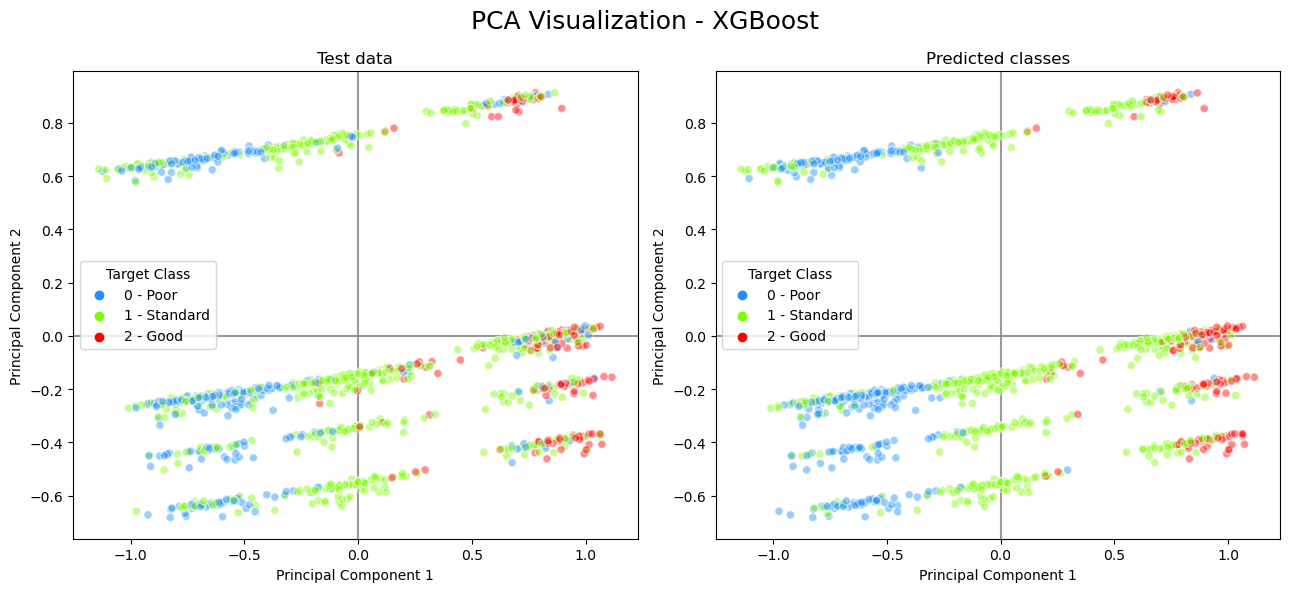

In [45]:
hf.pca_visualization(X_true=X_valid, 
                     y_true=y_valid, 
                     y_pred=y_pred_XGB_valid, 
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='XGBoost',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_test, 
                     y_true=y_test, 
                     y_pred=y_pred_XGB_test, 
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='XGBoost',
                     valid_or_test='Test',
                     alpha=0.45)

[0]	validation_0-mlogloss:0.91473
[10]	validation_0-mlogloss:0.59556
[20]	validation_0-mlogloss:0.58683
[30]	validation_0-mlogloss:0.59559
[40]	validation_0-mlogloss:0.60128
[50]	validation_0-mlogloss:0.60690
[60]	validation_0-mlogloss:0.61299
[67]	validation_0-mlogloss:0.62016
XGBoost training time: 0.16 seconds


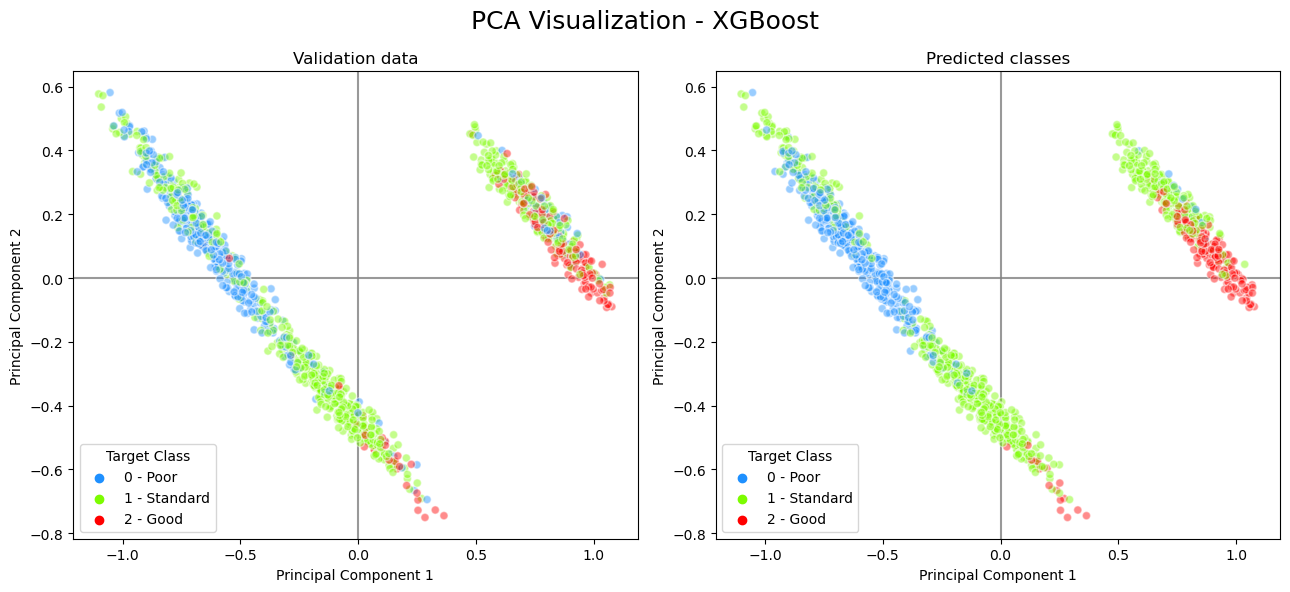

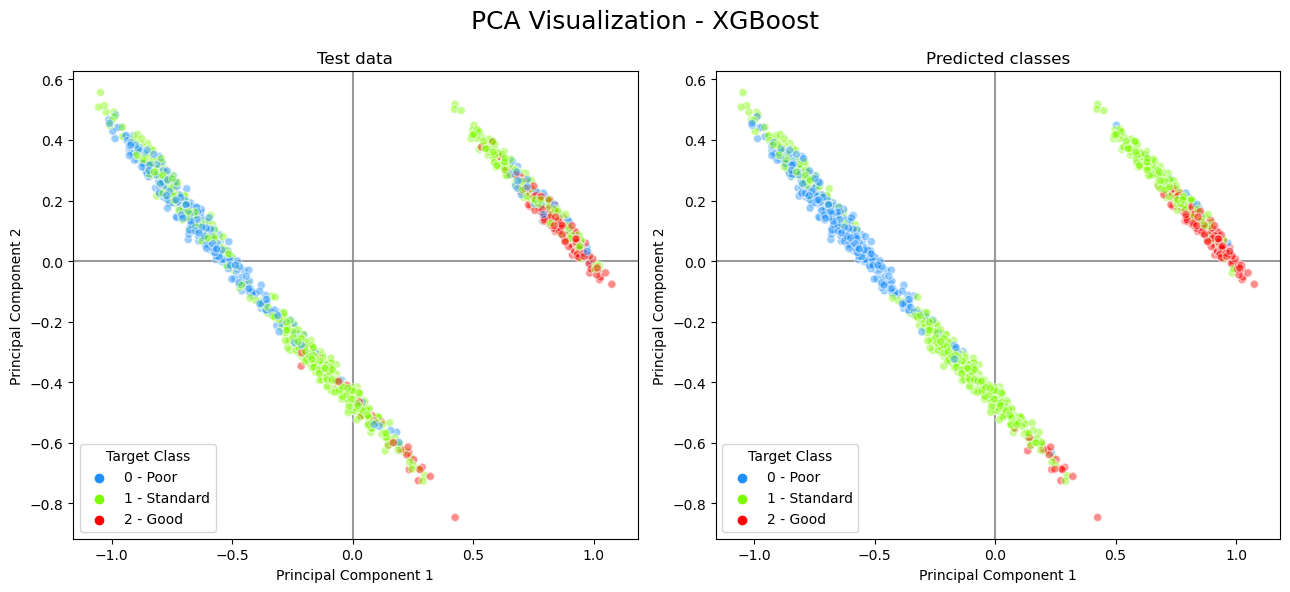

In [46]:
"""PCA for most important features based on feature importance plot"""
xgb_most_important_feats = xgb_feat_names_sorted_desc_by_importance[:8]
X_XGB_train_important_feats = X_train[ xgb_most_important_feats ]
X_XGB_valid_important_feats = X_valid[ xgb_most_important_feats ]
X_XGB_test_important_feats = X_test[ xgb_most_important_feats ]

"""Building XGBoost model using only most important features only for PCA visualization purposes"""
start_time = time.time()
xgb_model_important_feats = xgb.XGBClassifier(
    n_estimators=xgb_model.n_estimators,
	learning_rate=xgb_model.learning_rate,
	objective=xgb_model.objective,
	eval_metric=xgb_model.eval_metric,
	scale_pos_weight=xgb_model.scale_pos_weight,
	early_stopping_rounds=xgb_model.early_stopping_rounds,
	random_state=xgb_model.random_state
)

xgb_model_important_feats.fit(
    X=X_XGB_train_important_feats.to_numpy(), 
	y=y_train.to_numpy(),
	eval_set=[(X_XGB_valid_important_feats.to_numpy(), y_valid.to_numpy())],
	verbose=10
)
end_time = time.time()
print(f"XGBoost training time: {(end_time - start_time):.2f} seconds")

y_pred_XGB_valid_imp_feats = xgb_model_important_feats.predict( X_XGB_valid_important_feats )
y_pred_XGB_test_imp_feats = xgb_model_important_feats.predict( X_XGB_test_important_feats )

hf.pca_visualization(X_true=X_XGB_valid_important_feats, 
                     y_true=y_valid, 
                     y_pred=y_pred_XGB_valid_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='XGBoost',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_XGB_test_important_feats, 
                     y_true=y_test, 
                     y_pred=y_pred_XGB_test_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='XGBoost',
                     valid_or_test='Test',
                     alpha=0.45)


### Random Forest Classifier

In [47]:
from sklearn.ensemble import RandomForestClassifier

start_time = time.time()
rf_model = RandomForestClassifier(
    n_estimators=500,
    class_weight='balanced_subsample',
    random_state=random_state,
    n_jobs=-1
)

rf_model.fit(
    X=X_train, 
	y=y_train
)

end_time = time.time()
print(f"Random Forest training time: {(end_time - start_time):.2f} seconds")

y_probs_RF_train = rf_model.predict_proba(X_train)
y_probs_RF_valid = rf_model.predict_proba(X_valid)
y_probs_RF_test = rf_model.predict_proba(X_test)
y_pred_RF_train = rf_model.predict(X_train)
y_pred_RF_valid = rf_model.predict(X_valid) 
y_pred_RF_test = rf_model.predict(X_test)

Random Forest training time: 2.29 seconds


In [48]:
rf_model.estimators_[0].tree_.max_depth

31

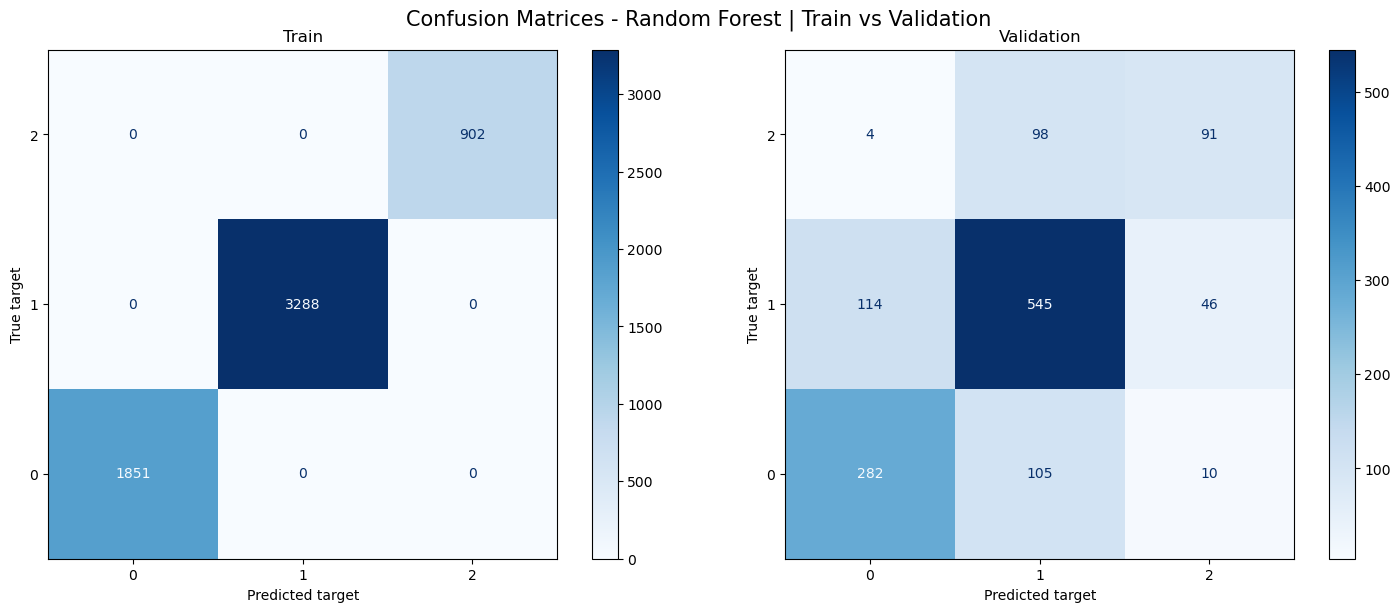

Train data:
Accuracy: 1.000
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      1851
           1      1.000     1.000     1.000      3288
           2      1.000     1.000     1.000       902

    accuracy                          1.000      6041
   macro avg      1.000     1.000     1.000      6041
weighted avg      1.000     1.000     1.000      6041


Validation data:
Accuracy: 0.709
              precision    recall  f1-score   support

           0      0.705     0.710     0.708       397
           1      0.729     0.773     0.750       705
           2      0.619     0.472     0.535       193

    accuracy                          0.709      1295
   macro avg      0.684     0.652     0.664      1295
weighted avg      0.705     0.709     0.705      1295



In [49]:
cm_train_RF, cm_valid_RF = hf.display_confusion_matrix(y1_true=y_train, 
                                                       y1_pred=y_pred_RF_train,
                                                       y2_true=y_valid, 
                                                       y2_pred=y_pred_RF_valid,
                                                       title='Confusion Matrices - Random Forest | Train vs Validation', 
                                                       cmap="Blues")  
hf.display_quality_metrics(y_true=y_train,
                           y_pred=y_pred_RF_train,
                           y_probs=y_probs_RF_train,
                           n_classes=3,
                           label='Train data',
                           pr_curve_title='PR AUC Random Forest - Train data')
hf.display_quality_metrics(y_true=y_valid,  
                           y_pred=y_pred_RF_valid,
                           y_probs=y_probs_RF_valid,
                           n_classes=3,
                           label='\nValidation data',
                           pr_curve_title='PR AUC Random Forest - Validation data')

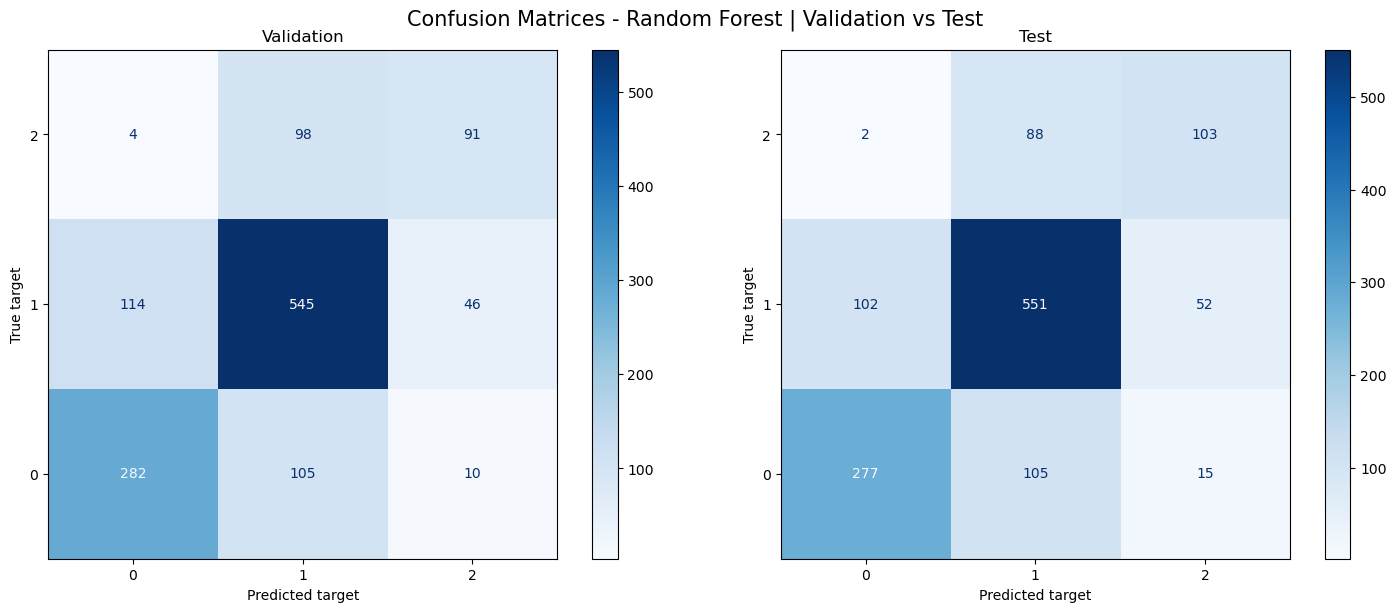

Validation data:
Accuracy: 0.709
              precision    recall  f1-score   support

           0      0.705     0.710     0.708       397
           1      0.729     0.773     0.750       705
           2      0.619     0.472     0.535       193

    accuracy                          0.709      1295
   macro avg      0.684     0.652     0.664      1295
weighted avg      0.705     0.709     0.705      1295


Test data:
Accuracy: 0.719
              precision    recall  f1-score   support

           0      0.727     0.698     0.712       397
           1      0.741     0.782     0.761       705
           2      0.606     0.534     0.567       193

    accuracy                          0.719      1295
   macro avg      0.691     0.671     0.680      1295
weighted avg      0.716     0.719     0.717      1295



In [50]:
cm_valid_RF, cm_test_RF = hf.display_confusion_matrix(y1_true=y_valid, 
                                                      y1_pred=y_pred_RF_valid,
                                                      y2_true=y_test, 
                                                      y2_pred=y_pred_RF_test,
                                                      title='Confusion Matrices - Random Forest | Validation vs Test', 
                                                      cmap="Blues",
                                                      compare=['Validation', 'Test'])  
hf.display_quality_metrics(y_true=y_valid,
                           y_pred=y_pred_RF_valid,
                           y_probs=y_probs_RF_valid,
                           n_classes=3,
                           label='Validation data',
                           pr_curve_title='PR AUC Random Forest - Validation data')
hf.display_quality_metrics(y_true=y_test,  
                           y_pred=y_pred_RF_test,
                           y_probs=y_probs_RF_test,
                           n_classes=3,
                           label='\nTest data',
                           pr_curve_title='PR AUC Random Forest - Test data')

#### Visualizing decision trees and feature importance for Random Forest model

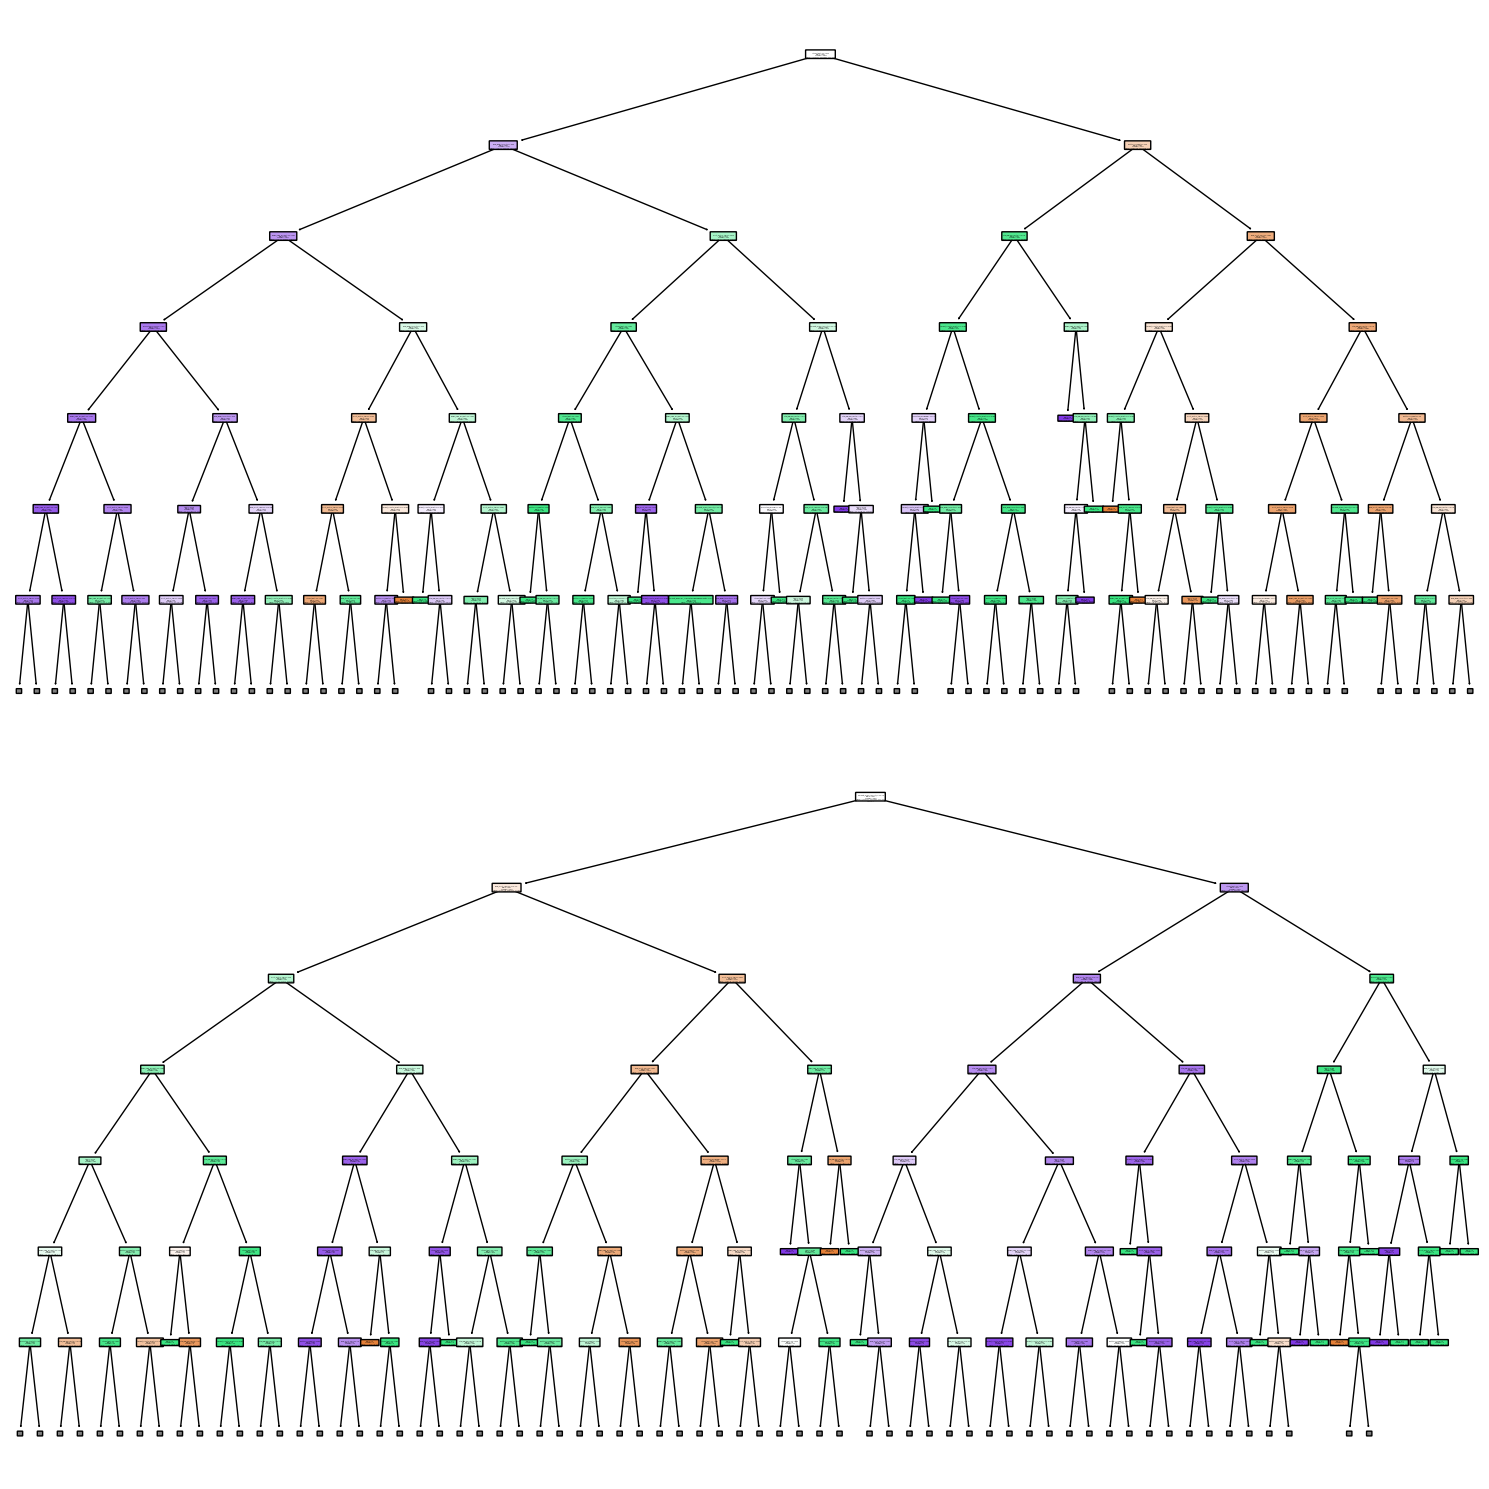

Calculating feature importances for Random forest model ...


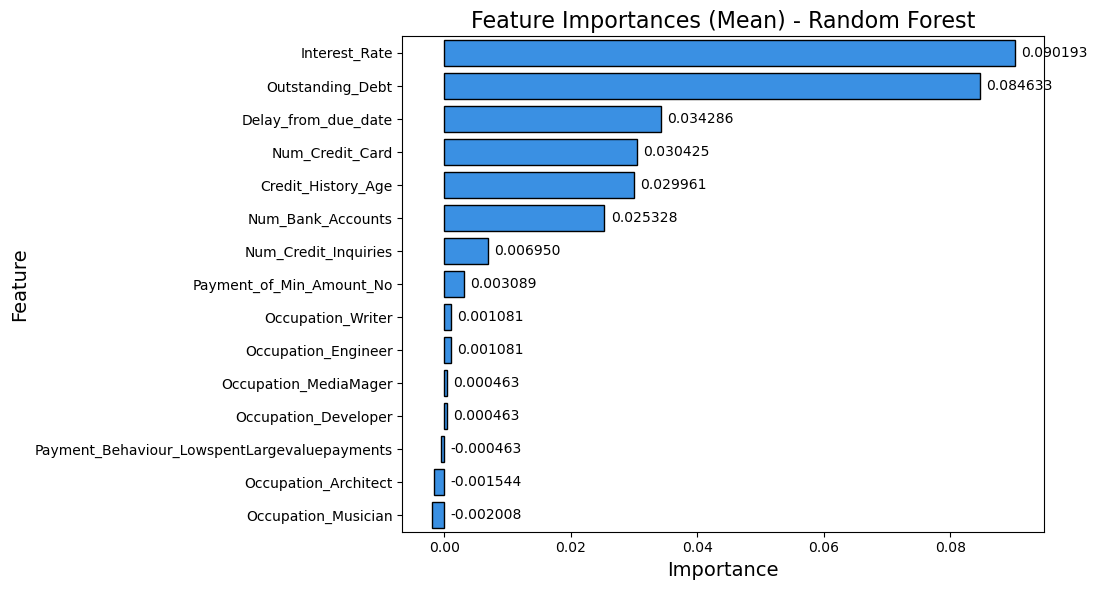

In [51]:
from sklearn import tree 

estimators_to_plot = [0, -1] # first and last trees in the forest
fig, axes = plt.subplots(len(estimators_to_plot), 1, figsize=(15, 15)); axes = axes.flatten()
max_depth = 6
for tree_i, ax in zip(estimators_to_plot, axes):
    tree.plot_tree(rf_model.estimators_[tree_i], 
                   feature_names=rf_model.feature_names_in_, 
                   class_names=rf_model.classes_.astype(str), 
                   filled=True,
                   rounded=True,
                   ax=ax,
                   max_depth=max_depth)
plt.tight_layout()
plt.show()

"""Plot feature importances for Random Forest model"""
rf_feat_names_sorted_desc_by_importance =  hf.plot_feature_importances(model=rf_model,
																	   model_name='Random Forest',
																	   X_data=X_valid,
																	   y_data=y_valid,
																	   n_reps=5,
																	   max_num_features=15,
																	   n_jobs=1)

#### PCA Visualization - Random Forest

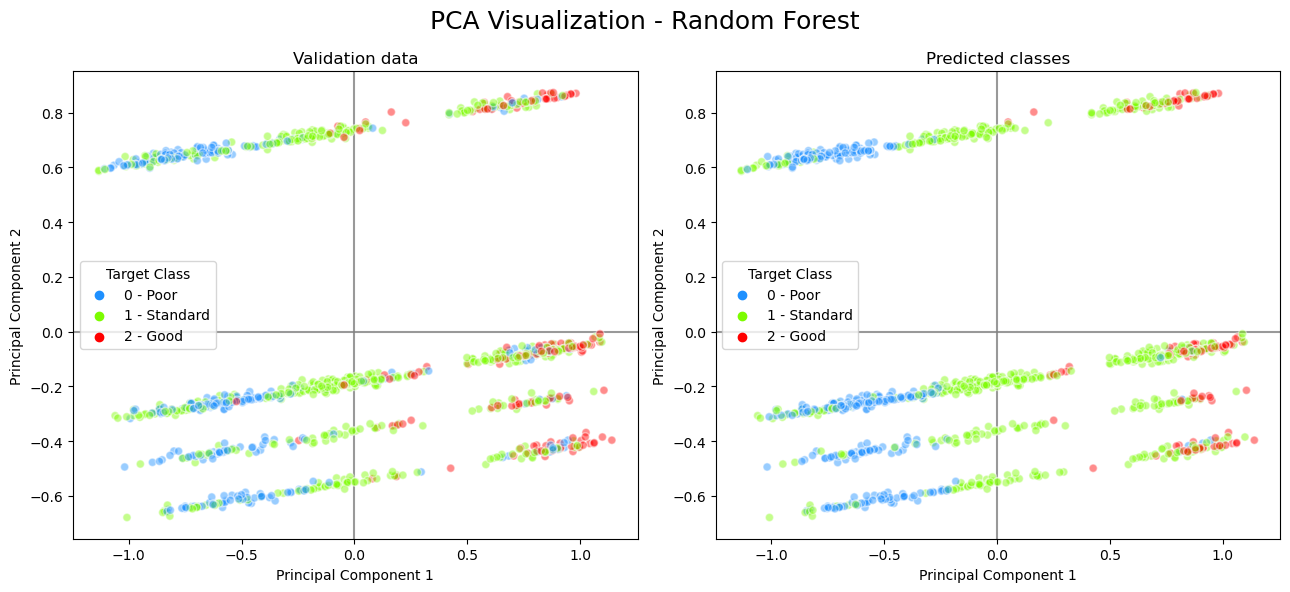

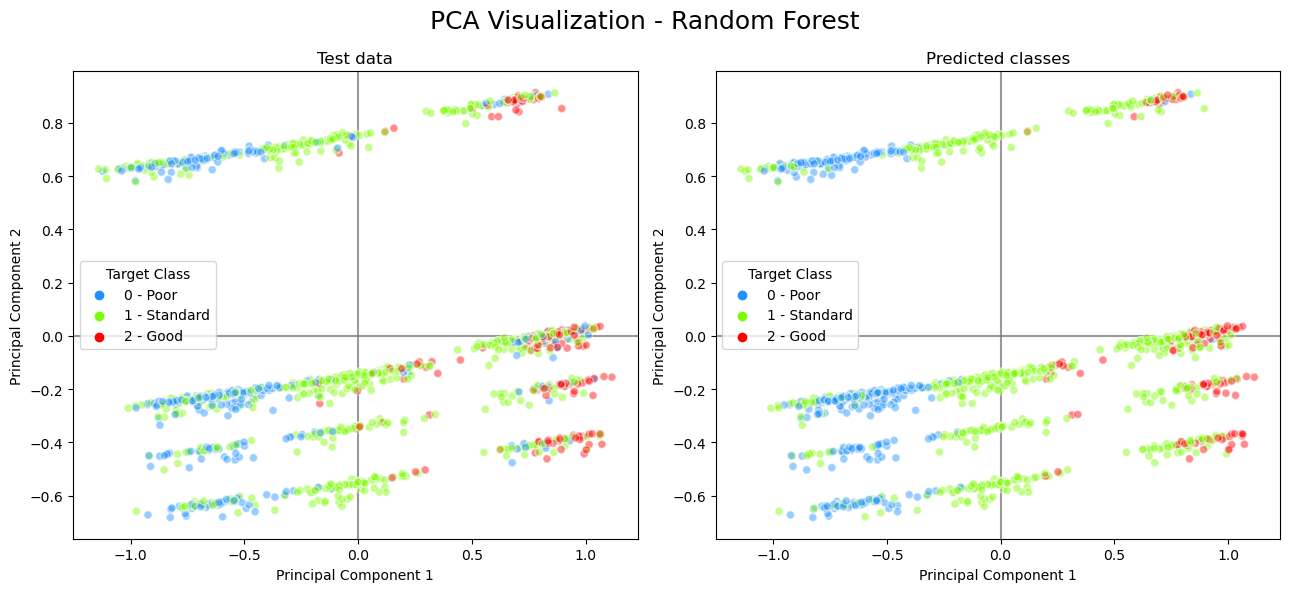

In [52]:
hf.pca_visualization(X_true=X_valid, 
                     y_true=y_valid, 
                     y_pred=y_pred_RF_valid,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Random Forest',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_test, 
                     y_true=y_test, 
                     y_pred=y_pred_RF_test,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Random Forest',
                     valid_or_test='Test',
                     alpha=0.45)

Random Forest training time: 2.21 seconds


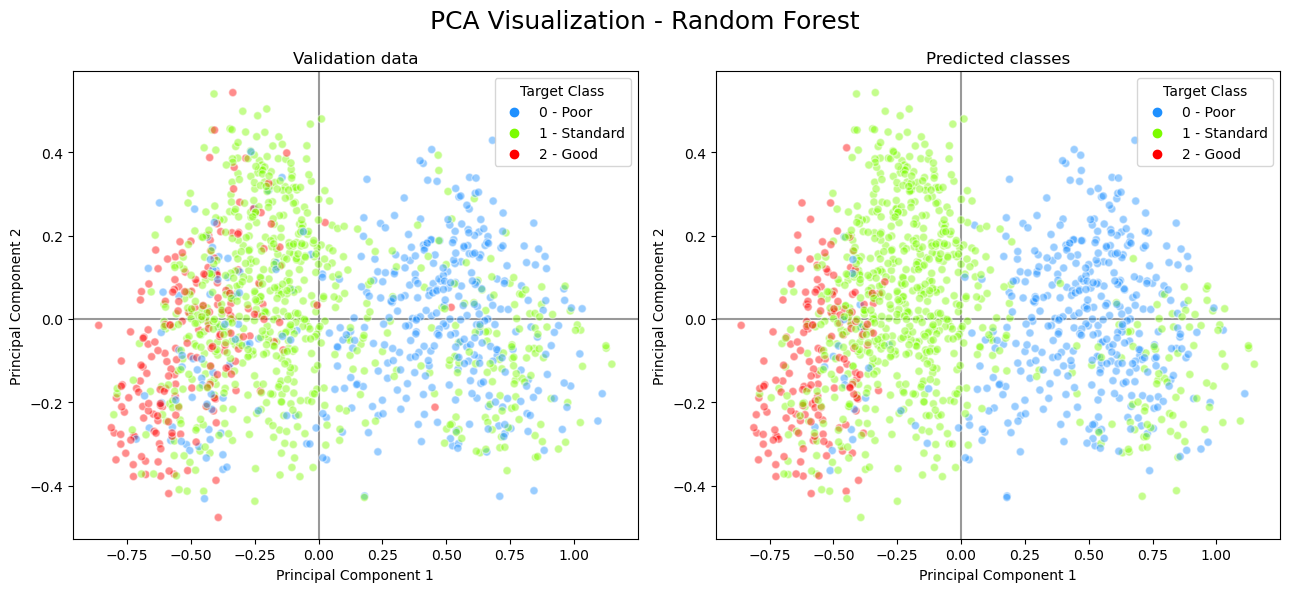

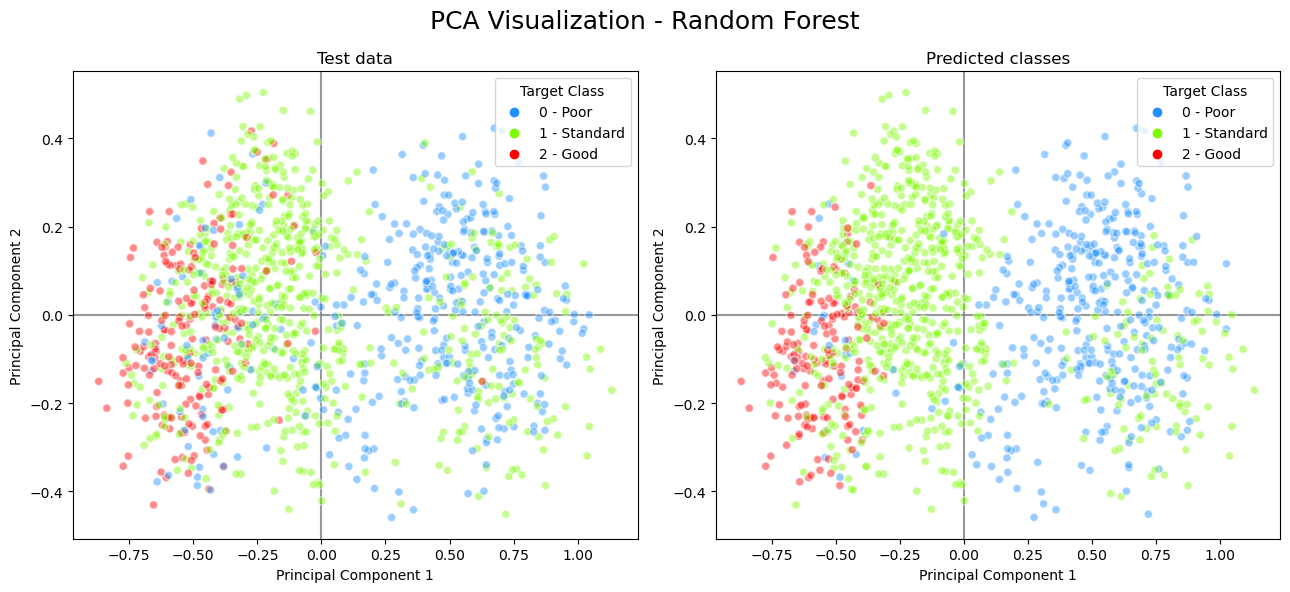

In [53]:
"""PCA for most important features based on feature importance plot"""
rf_most_important_feats = rf_feat_names_sorted_desc_by_importance[:6]
X_RF_train_important_feats = X_train[ rf_most_important_feats ]
X_RF_valid_important_feats = X_valid[ rf_most_important_feats ]
X_RF_test_important_feats = X_test[ rf_most_important_feats ]

"""Building Random Forest model using only most important features only for PCA visualization purposes"""
start_time = time.time()
rf_model_important_feats = RandomForestClassifier(
    n_estimators=rf_model.n_estimators,
	max_depth=rf_model.max_depth,
	min_samples_leaf=rf_model.min_samples_leaf,
	class_weight=rf_model.class_weight,
	random_state=rf_model.random_state,
	n_jobs=rf_model.n_jobs
)

rf_model_important_feats.fit(
    X=X_RF_train_important_feats, 
    y=y_train
)
end_time = time.time()
print(f"Random Forest training time: {(end_time - start_time):.2f} seconds")

y_pred_RF_valid_imp_feats = rf_model_important_feats.predict( X_RF_valid_important_feats )
y_pred_RF_test_imp_feats = rf_model_important_feats.predict( X_RF_test_important_feats )

hf.pca_visualization(X_true=X_RF_valid_important_feats, 
                     y_true=y_valid, 
                     y_pred=y_pred_RF_valid_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Random Forest',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_RF_test_important_feats, 
                     y_true=y_test, 
                     y_pred=y_pred_RF_test_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Random Forest',
                     valid_or_test='Test',
                     alpha=0.45)

### Neural Network for classification

#### Training of the Neural Network

In [54]:
import torch
print(torch.__config__.show())

PyTorch built with:
  - C++ Version: 201703
  - MSVC 192930151
  - Intel(R) Math Kernel Library Version 2020.0.2 Product Build 20200624 for Intel(R) 64 architecture applications
  - Intel(R) MKL-DNN v3.3.2 (Git Hash 2dc95a2ad0841e29db8b22fbccaf3e5da7992b01)
  - OpenMP 2019
  - LAPACK is enabled (usually provided by MKL)
  - CPU capability usage: AVX2
  - CUDA Runtime 12.1
  - NVCC architecture flags: -gencode;arch=compute_50,code=sm_50;-gencode;arch=compute_60,code=sm_60;-gencode;arch=compute_61,code=sm_61;-gencode;arch=compute_70,code=sm_70;-gencode;arch=compute_75,code=sm_75;-gencode;arch=compute_80,code=sm_80;-gencode;arch=compute_86,code=sm_86;-gencode;arch=compute_90,code=sm_90
  - CuDNN 8.8.1  (built against CUDA 12.0)
  - Magma 2.5.4
  - Build settings: BLAS_INFO=mkl, BUILD_TYPE=Release, CUDA_VERSION=12.1, CUDNN_VERSION=8.8.1, CXX_COMPILER=C:/cb/pytorch_1000000000000/work/tmp_bin/sccache-cl.exe, CXX_FLAGS=/DWIN32 /D_WINDOWS /GR /EHsc /Zc:__cplusplus /bigobj /FS /utf-8 -DUSE_PTHR

In [55]:
from nn_for_classification import NeuralNetClassifier

epochs = 5000
patience = 0.05 * epochs

start_time = time.time()
nn_classifier = NeuralNetClassifier(
    hidden_layers_sizes=[64, 32],
    dropout_prob=0.2,
    epochs=epochs,
    lr=0.001,
    patience=patience,
    random_state=random_state,
    device=device
)

nn_classifier.fit(
    X_train=X_train, 
    y_train=y_train, 
    X_valid=X_valid, 
    y_valid=y_valid
)
end_time = time.time()
print(f"\nNeural Network training time: {(end_time - start_time):.2f} seconds")

y_probs_NN_train = nn_classifier.predict_proba(X_train)
y_probs_NN_valid = nn_classifier.predict_proba(X_valid)
y_pred_NN_train = nn_classifier.predict(X_train)
y_pred_NN_valid = nn_classifier.predict(X_valid)

Epoch: 100 | Train loss: 0.74623 | Valid loss: 0.74168
Epoch: 200 | Train loss: 0.68506 | Valid loss: 0.68971
Epoch: 300 | Train loss: 0.66126 | Valid loss: 0.67112
Epoch: 400 | Train loss: 0.64409 | Valid loss: 0.65523
Epoch: 500 | Train loss: 0.62824 | Valid loss: 0.63814
Epoch: 600 | Train loss: 0.61786 | Valid loss: 0.63064
Epoch: 700 | Train loss: 0.60849 | Valid loss: 0.62824
Epoch: 800 | Train loss: 0.60443 | Valid loss: 0.62564
Epoch: 900 | Train loss: 0.59716 | Valid loss: 0.62486
Epoch: 1000 | Train loss: 0.59252 | Valid loss: 0.62560
Epoch: 1100 | Train loss: 0.58630 | Valid loss: 0.62361
Epoch: 1200 | Train loss: 0.58007 | Valid loss: 0.62539
Epoch: 1300 | Train loss: 0.58372 | Valid loss: 0.62501
Early stopping at epoch 1349 ...

Epoch: 1349 | Train loss: 0.57823 | Valid loss: 0.62514
Best model obtained at epoch 1099
Epoch: 1099 | Train loss: 0.58746 | Valid loss: 0.62359

Neural Network training time: 7.91 seconds


#### Installing hypopt package for hyperparameter tuning, it contains GridSearch class that enables including validation set in the training process

In [56]:
# !pip install hypopt

#### GridSearch attempt for neural network to find optimal parameters

In [57]:
"""
from hypopt import GridSearch

hidden_architectures = [[32],
                        [60],
                        [64],
                        [60, 30],
                        [64, 32], 
                        [64, 32, 16]]

params_grid = {
    'hidden_layers_sizes': [[32], [64], [60, 30]],
    'dropout_prob': [0.1, 0.2, 0.3],
    'regularization_type': [None, 'L1', 'L2'],
    'lambda_reg': [0.01, 0.1],
    'lr': [0.01, 0.001, 0.0005],
    'epochs': [epochs],
    'patience': [patience]
}

base_model = NeuralNetClassifier(device=device)
grid_search = GridSearch(
                    model=base_model,
                    param_grid=params_grid,
                    num_threads=6
)

grid_search.fit( X_train, y_train, X_valid, y_valid, scoring='f1', verbose=2 )
best_classifier = grid_search.best_estimator_

y_probs_NN_train = best_classifier.predict_proba(X_train)
y_probs_NN_valid = best_classifier.predict_proba(X_valid)
y_pred_NN_train = best_classifier.predict(X_train)
y_pred_NN_valid = best_classifier.predict(X_valid)
"""

"\nfrom hypopt import GridSearch\n\nhidden_architectures = [[32],\n                        [60],\n                        [64],\n                        [60, 30],\n                        [64, 32], \n                        [64, 32, 16]]\n\nparams_grid = {\n    'hidden_layers_sizes': [[32], [64], [60, 30]],\n    'dropout_prob': [0.1, 0.2, 0.3],\n    'regularization_type': [None, 'L1', 'L2'],\n    'lambda_reg': [0.01, 0.1],\n    'lr': [0.01, 0.001, 0.0005],\n    'epochs': [epochs],\n    'patience': [patience]\n}\n\nbase_model = NeuralNetClassifier(device=device)\ngrid_search = GridSearch(\n                    model=base_model,\n                    param_grid=params_grid,\n                    num_threads=6\n)\n\ngrid_search.fit( X_train, y_train, X_valid, y_valid, scoring='f1', verbose=2 )\nbest_classifier = grid_search.best_estimator_\n\ny_probs_NN_train = best_classifier.predict_proba(X_train)\ny_probs_NN_valid = best_classifier.predict_proba(X_valid)\ny_pred_NN_train = best_classifier

#### Training process visualisation

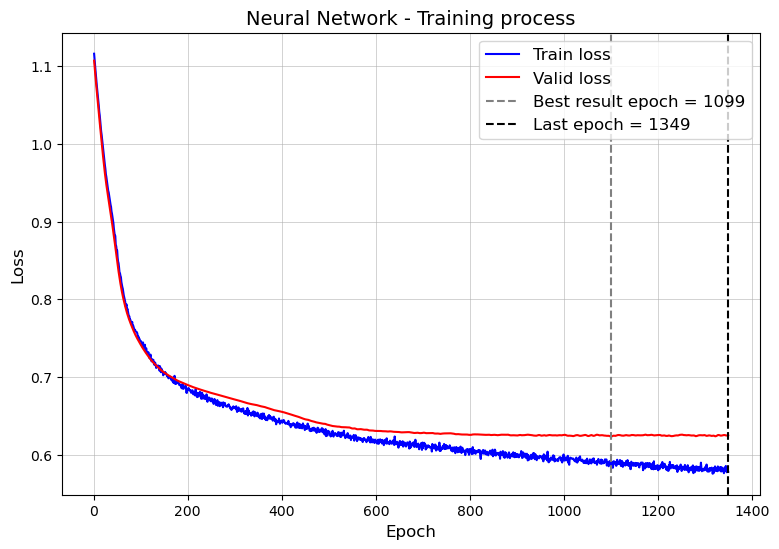

In [58]:
nn_last_model = nn_classifier.last_model
epochs_axis = range(1, nn_last_model.break_epoch + 1)
plt.figure(figsize=(9, 6))
plt.plot(epochs_axis, nn_last_model.train_losses, color='blue', linewidth=1.5, label='Train loss')
plt.plot(epochs_axis, nn_last_model.valid_losses, color='red', linewidth=1.5, label='Valid loss')
plt.axvline(x=nn_last_model.best_epoch, color='gray', linewidth=1.5, linestyle='--', label=f'Best result epoch = {nn_last_model.best_epoch}')
plt.axvline(x=nn_last_model.break_epoch, color='black', linewidth=1.5, linestyle='--', label=f'Last epoch = {nn_last_model.break_epoch}')
plt.title('Neural Network Training Process', fontsize=14)
plt.legend(fontsize=12, loc='upper right')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.title('Neural Network - Training process', fontsize=14)
plt.grid(linewidth=0.4)
plt.show()

#### Testing model on test data

In [59]:
"""Evaluating best model on test data"""
best_model = nn_classifier.best_model

"""Model structure"""
print(best_model.layer_stack)

"""predict_proba() and predict() methods use best model"""
y_probs_NN_test = nn_classifier.predict_proba(X_test)
y_pred_NN_test = nn_classifier.predict(X_test)
# Loss on test data
X_test_tensor = torch.tensor(X_test.to_numpy(), dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)
y_test_logits = best_model(X_test_tensor).squeeze() # forward step to get logits for test data
test_loss = best_model.loss_fn(y_test_logits, y_test_tensor).item()
print(f"Test loss: {test_loss:.5f}")

Sequential(
  (0): Linear(in_features=20, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=32, out_features=3, bias=True)
)
Test loss: 0.62924


#### Results for train and validation data set

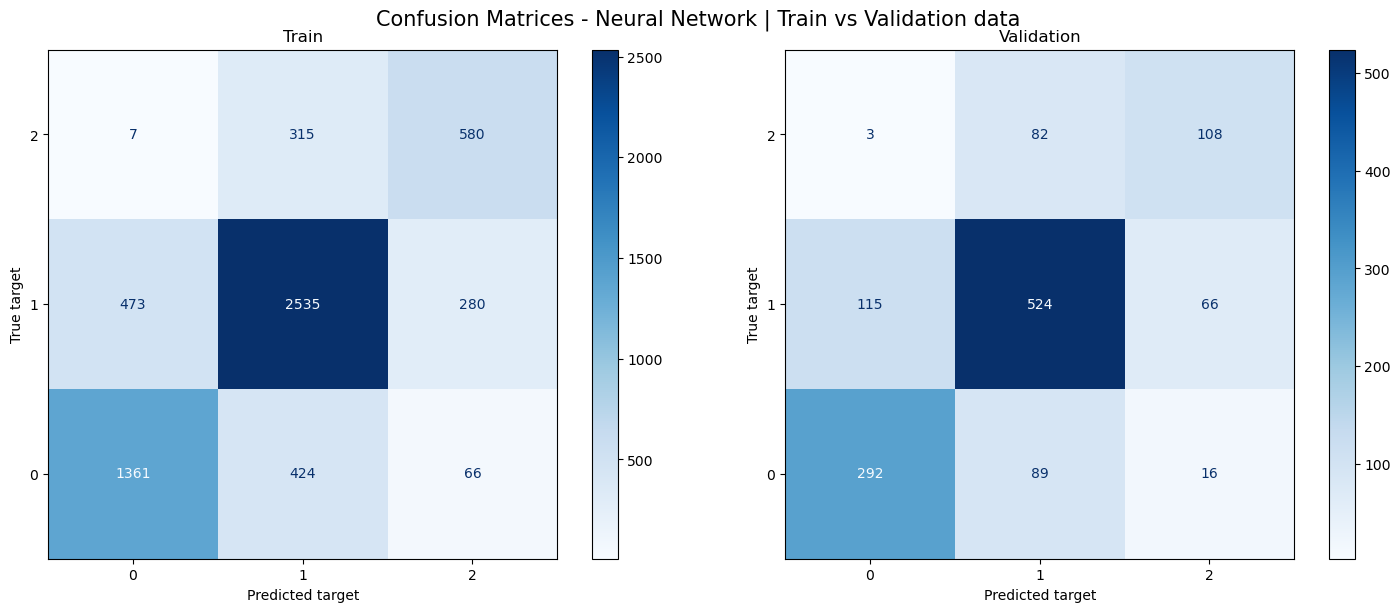

Train data:
Accuracy: 0.741
              precision    recall  f1-score   support

           0      0.739     0.735     0.737      1851
           1      0.774     0.771     0.773      3288
           2      0.626     0.643     0.635       902

    accuracy                          0.741      6041
   macro avg      0.713     0.716     0.715      6041
weighted avg      0.741     0.741     0.741      6041


Validation data:
Accuracy: 0.714
              precision    recall  f1-score   support

           0      0.712     0.736     0.724       397
           1      0.754     0.743     0.749       705
           2      0.568     0.560     0.564       193

    accuracy                          0.714      1295
   macro avg      0.678     0.679     0.679      1295
weighted avg      0.714     0.714     0.713      1295



In [60]:
cm_train_NN, cm_valid_NN = hf.display_confusion_matrix(y1_true=y_train,
                                                       y1_pred=y_pred_NN_train,
                                                       y2_true=y_valid,
                                                       y2_pred=y_pred_NN_valid,
                                                       title='Confusion Matrices - Neural Network | Train vs Validation data', 
                                                       cmap="Blues")
hf.display_quality_metrics(y_true=y_train,
                           y_pred=y_pred_NN_train,
                           y_probs=y_probs_NN_train,
                           n_classes=3,
                           label='Train data',
                           pr_curve_title='PR AUC Neural Network - Train data')
hf.display_quality_metrics(y_true=y_valid,
                           y_pred=y_pred_NN_valid,
                           y_probs=y_probs_NN_valid,
                           n_classes=3,
                           label='\nValidation data',
                           pr_curve_title='PR AUC Neural Network - Validation data')

#### Results for validation and test data set

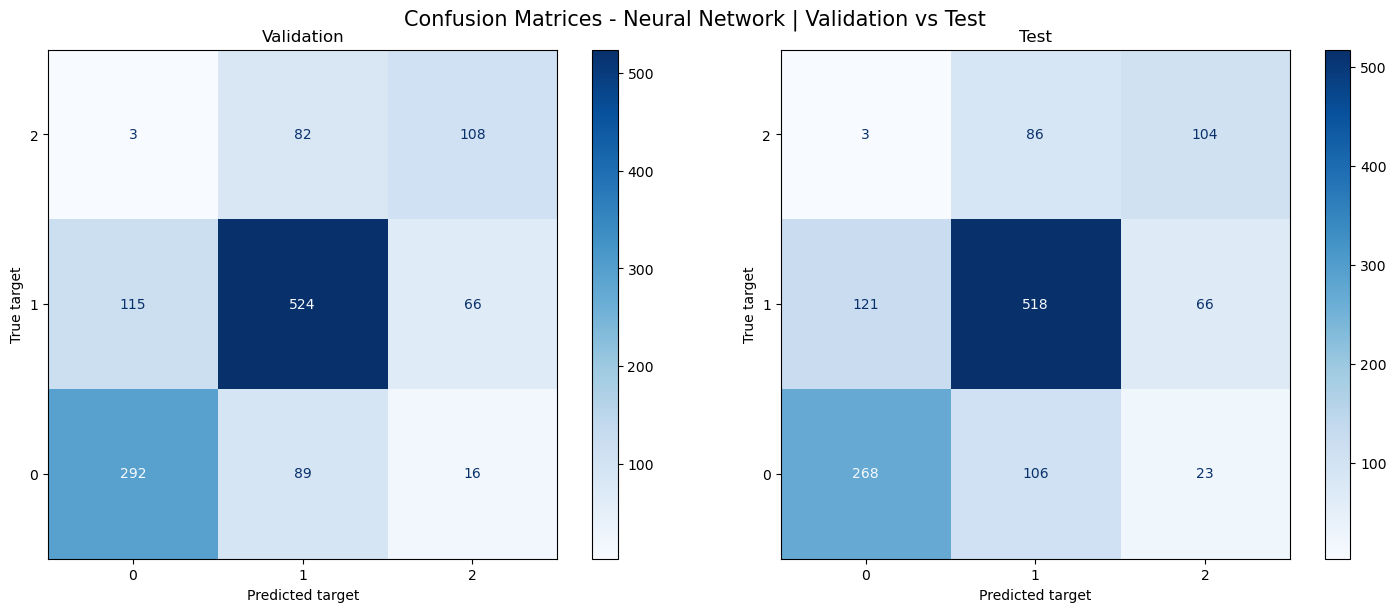

Validation data:
Accuracy: 0.714
              precision    recall  f1-score   support

           0      0.712     0.736     0.724       397
           1      0.754     0.743     0.749       705
           2      0.568     0.560     0.564       193

    accuracy                          0.714      1295
   macro avg      0.678     0.679     0.679      1295
weighted avg      0.714     0.714     0.713      1295


Test data:
Accuracy: 0.687
              precision    recall  f1-score   support

           0      0.684     0.675     0.679       397
           1      0.730     0.735     0.732       705
           2      0.539     0.539     0.539       193

    accuracy                          0.687      1295
   macro avg      0.651     0.650     0.650      1295
weighted avg      0.687     0.687     0.687      1295



In [61]:
cm_valid_NN, cm_test_NN = hf.display_confusion_matrix(y1_true=y_valid,
                                                      y1_pred=y_pred_NN_valid,
                                                      y2_true=y_test,
                                                      y2_pred=y_pred_NN_test,
                                                      title='Confusion Matrices - Neural Network | Validation vs Test', 
                                                      cmap="Blues",
                                                      compare=['Validation', 'Test'])
hf.display_quality_metrics(y_true=y_valid,
                           y_pred=y_pred_NN_valid,
                           y_probs=y_probs_NN_valid,
                           n_classes=3,
                           label='Validation data',
                           pr_curve_title='PR AUC Neural Network - Validation data')
hf.display_quality_metrics(y_true=y_test,
                           y_pred=y_pred_NN_test,
                           y_probs=y_probs_NN_test,
                           n_classes=3,
                           label='\nTest data',
                           pr_curve_title='PR AUC Neural Network - Test data')

Calculating feature importances for Neural network model ...


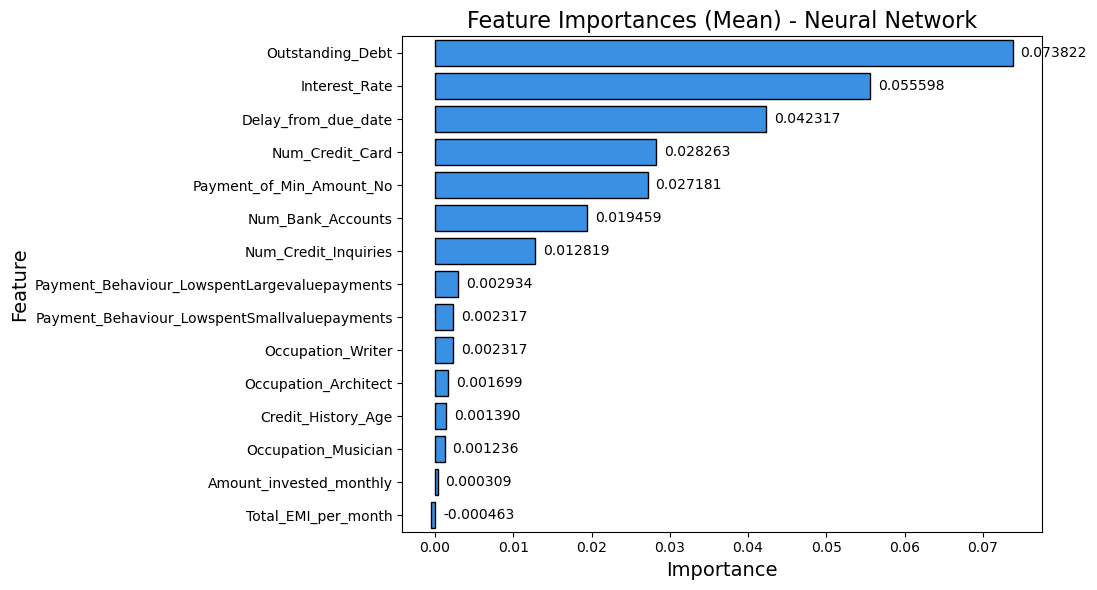

In [62]:
"""Plot feature importances for Neural Network model"""
nn_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(model=nn_classifier,
																	  model_name='Neural Network',
																	  X_data=X_valid,
																	  y_data=y_valid,
																      n_reps=5,
																	  max_num_features=15,
																	  n_jobs=1)

#### PCA Visualisation - Neural Network

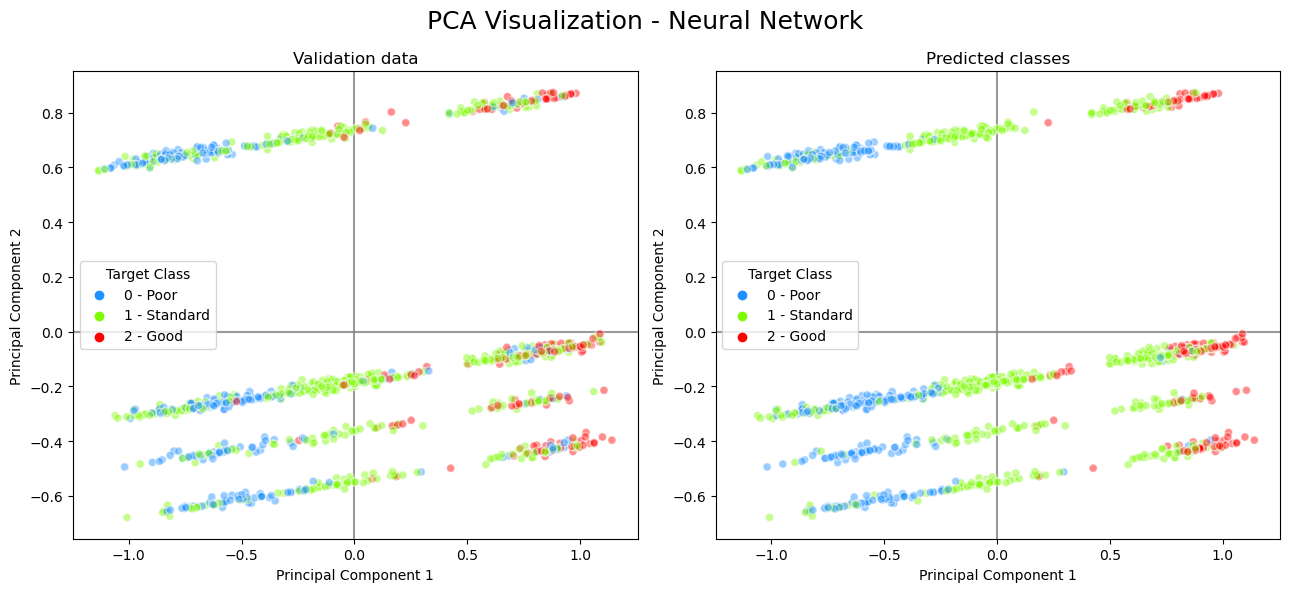

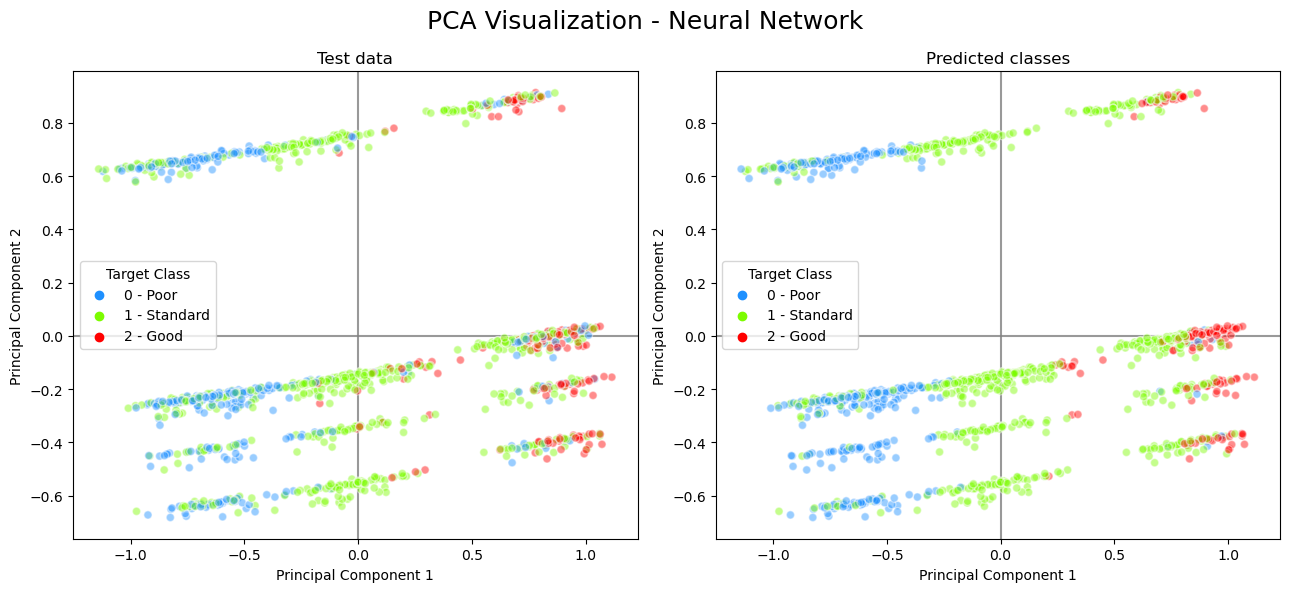

In [63]:
hf.pca_visualization(X_true=X_valid,
                     y_true=y_valid,
                     y_pred=y_pred_NN_valid,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Neural Network',
                     valid_or_test='Validation',
                     alpha=0.45)
hf.pca_visualization(X_true=X_test,
                     y_true=y_test,
                     y_pred=y_pred_NN_test,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Neural Network',
                     valid_or_test='Test',
                     alpha=0.45)

Epoch: 100 | Train loss: 0.74828 | Valid loss: 0.72607
Epoch: 200 | Train loss: 0.67843 | Valid loss: 0.66514
Epoch: 300 | Train loss: 0.65406 | Valid loss: 0.64099
Epoch: 400 | Train loss: 0.63519 | Valid loss: 0.62920
Epoch: 500 | Train loss: 0.62782 | Valid loss: 0.62229
Epoch: 600 | Train loss: 0.62769 | Valid loss: 0.61791
Epoch: 700 | Train loss: 0.62371 | Valid loss: 0.61460
Epoch: 800 | Train loss: 0.61850 | Valid loss: 0.61213
Epoch: 900 | Train loss: 0.61664 | Valid loss: 0.61112
Epoch: 1000 | Train loss: 0.61346 | Valid loss: 0.60951
Epoch: 1100 | Train loss: 0.61019 | Valid loss: 0.60846
Epoch: 1200 | Train loss: 0.60867 | Valid loss: 0.60713
Epoch: 1300 | Train loss: 0.60928 | Valid loss: 0.60685
Epoch: 1400 | Train loss: 0.60523 | Valid loss: 0.60672
Epoch: 1500 | Train loss: 0.60541 | Valid loss: 0.60576
Epoch: 1600 | Train loss: 0.59832 | Valid loss: 0.60559
Epoch: 1700 | Train loss: 0.59897 | Valid loss: 0.60509
Epoch: 1800 | Train loss: 0.60163 | Valid loss: 0.60484
E

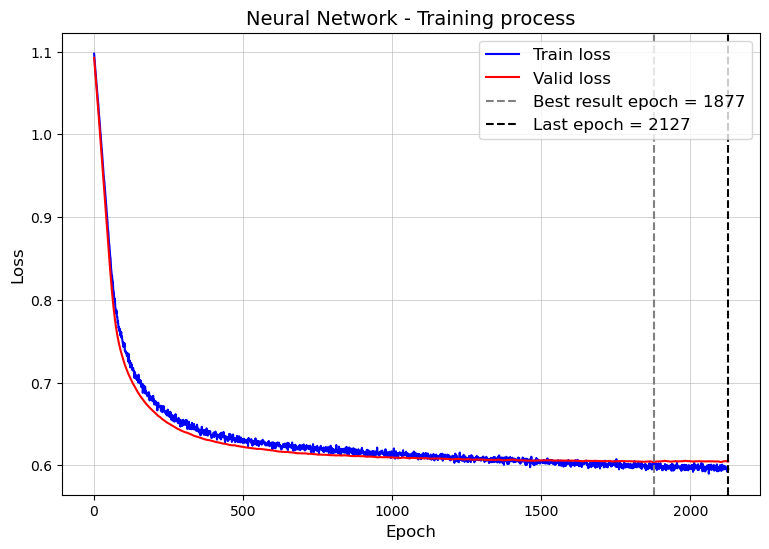

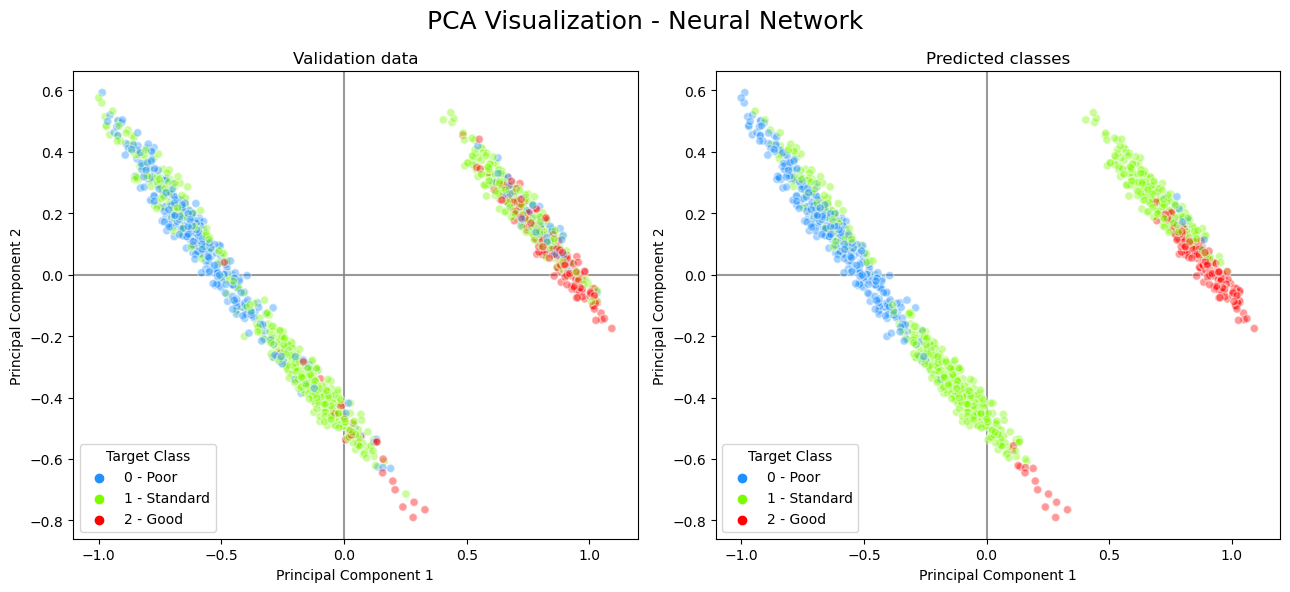

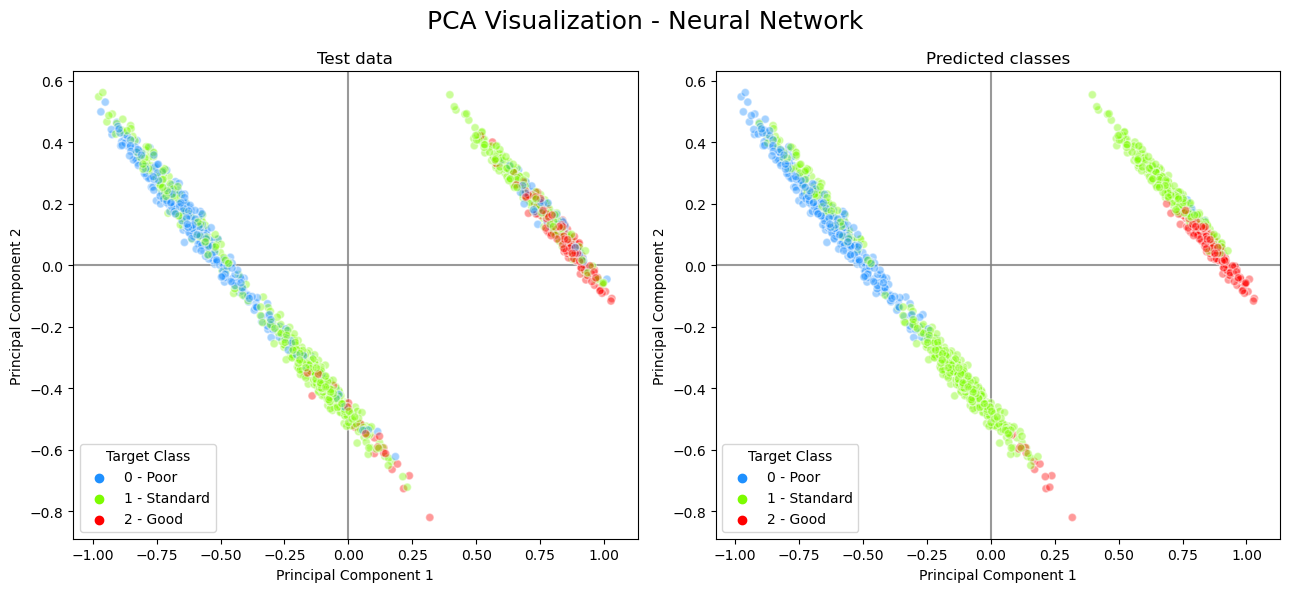

In [64]:
"""PCA for most important features based on feature importance plot"""
nn_most_important_feats = nn_feat_names_sorted_desc_by_importance[:7]
X_NN_train_important_feats = X_train[ nn_most_important_feats ]
X_NN_valid_important_feats = X_valid[ nn_most_important_feats ]
X_NN_test_important_feats = X_test[ nn_most_important_feats ]

"""Building Neural Network model using only most important features only for PCA visualization purposes"""
start_time = time.time()
nn_classifier_important_feats = NeuralNetClassifier(
    		hidden_layers_sizes=nn_classifier.hidden_layers_sizes,
            dropout_prob=nn_classifier.dropout_prob,
            epochs=nn_classifier.epochs,
            lr=nn_classifier.lr,
            patience=nn_classifier.patience,
            random_state=nn_classifier.random_state,
            device=nn_classifier.device
		)
nn_classifier_important_feats.fit(
    X_train=X_NN_train_important_feats, 
    y_train=y_train, 
    X_valid=X_NN_valid_important_feats, 
    y_valid=y_valid
)
end_time = time.time()
print(f"\nNeural Network training time: {(end_time - start_time):.2f} seconds")

y_pred_NN_valid_imp_feats = nn_classifier_important_feats.predict( X_NN_valid_important_feats )
y_pred_NN_test_imp_feats = nn_classifier_important_feats.predict( X_NN_test_important_feats )

nn_imp_feats_last_model = nn_classifier_important_feats.last_model
epochs_axis = range(1, nn_imp_feats_last_model.break_epoch + 1)
plt.figure(figsize=(9, 6))
plt.plot(epochs_axis, nn_imp_feats_last_model.train_losses, color='blue', linewidth=1.5, label='Train loss')
plt.plot(epochs_axis, nn_imp_feats_last_model.valid_losses, color='red', linewidth=1.5, label='Valid loss')
plt.axvline(x=nn_imp_feats_last_model.best_epoch, color='gray', linewidth=1.5, linestyle='--', label=f'Best result epoch = {nn_imp_feats_last_model.best_epoch}')
plt.axvline(x=nn_imp_feats_last_model.break_epoch, color='black', linewidth=1.5, linestyle='--', label=f'Last epoch = {nn_imp_feats_last_model.break_epoch}')
plt.title('Neural Network Training Process', fontsize=14)
plt.legend(fontsize=12, loc='upper right')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.title('Neural Network - Training process', fontsize=14)
plt.grid(linewidth=0.4)
plt.show()

hf.pca_visualization(X_true=X_NN_valid_important_feats, 
                     y_true=y_valid, 
                     y_pred=y_pred_NN_valid_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Neural Network',
                     valid_or_test='Validation',
                     alpha=0.4)
hf.pca_visualization(X_true=X_NN_test_important_feats, 
                     y_true=y_test, 
                     y_pred=y_pred_NN_test_imp_feats,
                     n_classes=3,
                     colors_dict=colors_dict,
                     class_names_dict=class_names_dict,
                     model_name='Neural Network',
                     valid_or_test='Test',
                     alpha=0.4)

In [65]:
gloabl_end_time = time.time()
print(f"Total execution time: {(gloabl_end_time - gloabl_start_time):.2f} seconds")

Total execution time: 110.36 seconds
